In [16]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import os
import seaborn
import pickle
from tqdm import tqdm
from pandas import HDFStore
from scipy.sparse.linalg import svds, eigs
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

In [18]:
#reading
from pandas import read_hdf
df_final_train = read_hdf('storage_sample_stage4.h5', 'train_df',mode='r')
df_final_test = read_hdf('storage_sample_stage4.h5', 'test_df',mode='r')

In [19]:
# Save the train and test datasets to CSV files
df_final_train.to_csv('featured_train_data.csv', index=False)
df_final_test.to_csv('featured_test_data.csv', index=False)

print("Train data saved as 'featured_train_data.csv'")
print("Test data saved as 'featured_test_data.csv'")

Train data saved as 'featured_train_data.csv'
Test data saved as 'featured_test_data.csv'


In [20]:
adi = pd.read_csv('featured_train_data.csv')
adi.head()
print(adi.value_counts('indicator_link'))

indicator_link
1    50050
0    49952
Name: count, dtype: int64


In [21]:
df_final_train.columns

Index(['source_node', 'destination_node', 'indicator_link',
       'jaccard_followers', 'jaccard_followees', 'cosine_followers',
       'cosine_followees', 'num_followers_s', 'num_followees_s',
       'num_followees_d', 'inter_followers', 'inter_followees', 'adar_index',
       'follows_back', 'same_comp', 'shortest_path', 'weight_in', 'weight_out',
       'weight_f1', 'weight_f2', 'weight_f3', 'weight_f4', 'page_rank_s',
       'page_rank_d', 'katz_s', 'katz_d', 'hubs_s', 'hubs_d', 'authorities_s',
       'authorities_d', 'svd_u_s_1', 'svd_u_s_2', 'svd_u_s_3', 'svd_u_s_4',
       'svd_u_s_5', 'svd_u_s_6', 'svd_u_d_1', 'svd_u_d_2', 'svd_u_d_3',
       'svd_u_d_4', 'svd_u_d_5', 'svd_u_d_6', 'svd_v_s_1', 'svd_v_s_2',
       'svd_v_s_3', 'svd_v_s_4', 'svd_v_s_5', 'svd_v_s_6', 'svd_v_d_1',
       'svd_v_d_2', 'svd_v_d_3', 'svd_v_d_4', 'svd_v_d_5', 'svd_v_d_6'],
      dtype='object')

In [22]:
df_final_train.tail()

,source_node,destination_node,indicator_link,jaccard_followers,jaccard_followees,cosine_followers,cosine_followees,num_followers_s,num_followees_s,num_followees_d,...,svd_v_s_3,svd_v_s_4,svd_v_s_5,svd_v_s_6,svd_v_d_1,svd_v_d_2,svd_v_d_3,svd_v_d_4,svd_v_d_5,svd_v_d_6
99997,139353,893843,0,0,0.0,0.0,0.0,7,1,10,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.303718e-12,1.538318e-13,1.296745e-06,2.990887e-13,1.589668e-12,7.338551e-14
99998,910842,704068,0,0,0.0,0.0,0.0,0,4,1,...,1.336987e-12,4.493330e-15,4.528679e-14,5.475207e-18,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
99999,794228,1172755,0,0,0.0,0.0,0.0,0,5,1,...,2.154438e-11,1.566738e-12,2.294564e-13,3.493379e-14,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
100000,949992,1854931,0,0,0.0,0.0,0.0,1,2,0,...,1.620187e-11,1.325874e-15,2.066643e-14,2.662102e-16,-1.142753e-17,5.200344e-17,3.858875e-15,2.173437e-17,2.241477e-16,3.528355e-20
100001,1642037,1090977,0,0,0.0,0.0,0.0,1,14,0,...,7.778089e-09,8.005625e-13,9.429577e-11,7.386157e-14,-1.657134e-14,2.085059e-14,2.107704e-07,2.652994e-12,2.004727e-14,2.805020e-14


In [7]:
y_train = df_final_train.indicator_link
y_test = df_final_test.indicator_link

In [8]:
df_final_train.drop(['source_node', 'destination_node','indicator_link'],axis=1,inplace=True)
df_final_test.drop(['source_node', 'destination_node','indicator_link'],axis=1,inplace=True)

In [9]:
df_final_train.tail()

,jaccard_followers,jaccard_followees,cosine_followers,cosine_followees,num_followers_s,num_followees_s,num_followees_d,inter_followers,inter_followees,adar_index,...,svd_v_s_3,svd_v_s_4,svd_v_s_5,svd_v_s_6,svd_v_d_1,svd_v_d_2,svd_v_d_3,svd_v_d_4,svd_v_d_5,svd_v_d_6
99997,0,0.0,0.0,0.0,7,1,10,0,0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.303718e-12,1.538318e-13,1.296745e-06,2.990887e-13,1.589668e-12,7.338551e-14
99998,0,0.0,0.0,0.0,0,4,1,0,0,0.0,...,1.336987e-12,4.493330e-15,4.528679e-14,5.475207e-18,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
99999,0,0.0,0.0,0.0,0,5,1,0,0,0.0,...,2.154438e-11,1.566738e-12,2.294564e-13,3.493379e-14,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
100000,0,0.0,0.0,0.0,1,2,0,0,0,0.0,...,1.620187e-11,1.325874e-15,2.066643e-14,2.662102e-16,-1.142753e-17,5.200344e-17,3.858875e-15,2.173437e-17,2.241477e-16,3.528355e-20
100001,0,0.0,0.0,0.0,1,14,0,0,0,0.0,...,7.778089e-09,8.005625e-13,9.429577e-11,7.386157e-14,-1.657134e-14,2.085059e-14,2.107704e-07,2.652994e-12,2.004727e-14,2.805020e-14


Estimators =  10 Train Score 0.9063252121775113 Test Score 0.8745605278006858
Estimators =  50 Train Score 0.9205725512208813 Test Score 0.9125653355634539
Estimators =  100 Train Score 0.9238690848446947 Test Score 0.91411997141536
Estimators =  250 Train Score 0.9239789348046863 Test Score 0.9188007232664732
Estimators =  450 Train Score 0.9237190618658074 Test Score 0.9161507685828596


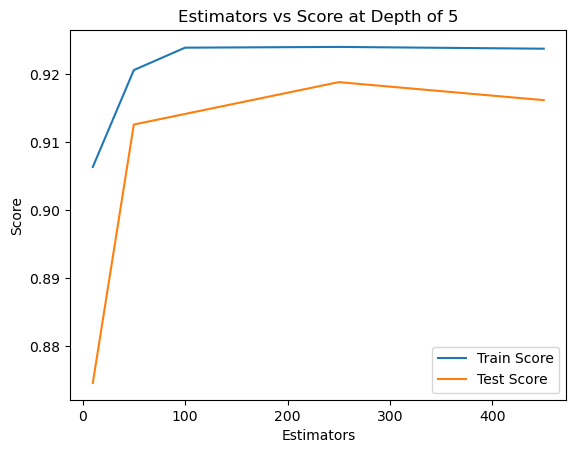

In [11]:
estimators = [10, 50, 100, 250, 450]
train_scores = []
test_scores = []

for i in estimators:
    clf = RandomForestClassifier(
        bootstrap=True,
        class_weight=None,
        criterion='gini',
        max_depth=5,
        max_features='sqrt',
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,  # This is valid
        min_samples_leaf=52,
        min_samples_split=120,
        min_weight_fraction_leaf=0.0,
        n_estimators=i,
        n_jobs=-1,
        random_state=25,
        verbose=0,
        warm_start=False
    )
    clf.fit(df_final_train, y_train)
    train_sc = f1_score(y_train, clf.predict(df_final_train))
    test_sc = f1_score(y_test, clf.predict(df_final_test))
    test_scores.append(test_sc)
    train_scores.append(train_sc)
    print('Estimators = ', i, 'Train Score', train_sc, 'Test Score', test_sc)

plt.plot(estimators, train_scores, label='Train Score')
plt.plot(estimators, test_scores, label='Test Score')
plt.xlabel('Estimators')
plt.ylabel('Score')
plt.title('Estimators vs Score at Depth of 5')
plt.legend()
plt.show()

depth =  3 Train Score 0.8964289081404971 test Score 0.8774484755578266
depth =  9 Train Score 0.9581477820464481 test Score 0.9245867115931347
depth =  11 Train Score 0.9617793659333854 test Score 0.9251935375294513
depth =  15 Train Score 0.9639261063743403 test Score 0.9265346492981754
depth =  20 Train Score 0.9638992101683215 test Score 0.9268015410201891
depth =  35 Train Score 0.964 test Score 0.926885749773689
depth =  50 Train Score 0.964 test Score 0.926885749773689
depth =  70 Train Score 0.964 test Score 0.926885749773689
depth =  130 Train Score 0.964 test Score 0.926885749773689


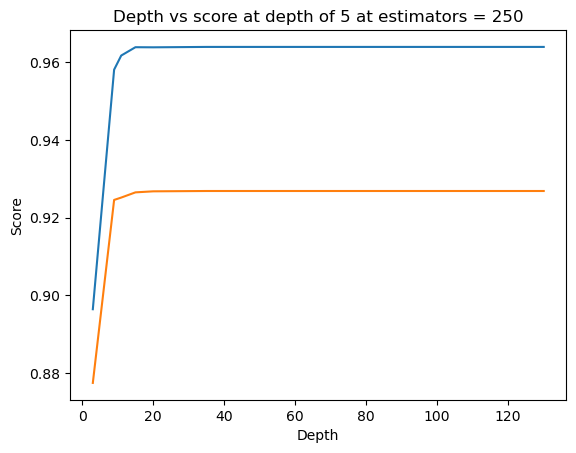

In [12]:
depths = [3,9,11,15,20,35,50,70,130]
train_scores = []
test_scores = []
for i in depths:
    clf = RandomForestClassifier(bootstrap=True, class_weight=None, criterion='gini',
            max_depth=i, max_features='sqrt', max_leaf_nodes=None,
            min_impurity_decrease=0.0, 
            min_samples_leaf=52, min_samples_split=120,
            min_weight_fraction_leaf=0.0, n_estimators=250, n_jobs=-1,random_state=25,verbose=0,warm_start=False)
    clf.fit(df_final_train,y_train)
    train_sc = f1_score(y_train,clf.predict(df_final_train))
    test_sc = f1_score(y_test,clf.predict(df_final_test))
    test_scores.append(test_sc)
    train_scores.append(train_sc)
    print('depth = ',i,'Train Score',train_sc,'test Score',test_sc)
plt.plot(depths,train_scores,label='Train Score')
plt.plot(depths,test_scores,label='Test Score')
plt.xlabel('Depth')
plt.ylabel('Score')
plt.title('Depth vs score at depth of 5 at estimators = 250')
plt.show()

depth =  3 Train Score 0.8916120853581239 test Score 0.8687934859875492
depth =  9 Train Score 0.9572226298198419 test Score 0.9222953031452905
depth =  11 Train Score 0.9623451340902864 test Score 0.9252318758281279
depth =  15 Train Score 0.9634267621927706 test Score 0.9231288356496615
depth =  20 Train Score 0.9631629153051491 test Score 0.9235051024711141
depth =  35 Train Score 0.9634333127085721 test Score 0.9235601652753184
depth =  50 Train Score 0.9634333127085721 test Score 0.9235601652753184
depth =  70 Train Score 0.9634333127085721 test Score 0.9235601652753184
depth =  130 Train Score 0.9634333127085721 test Score 0.9235601652753184


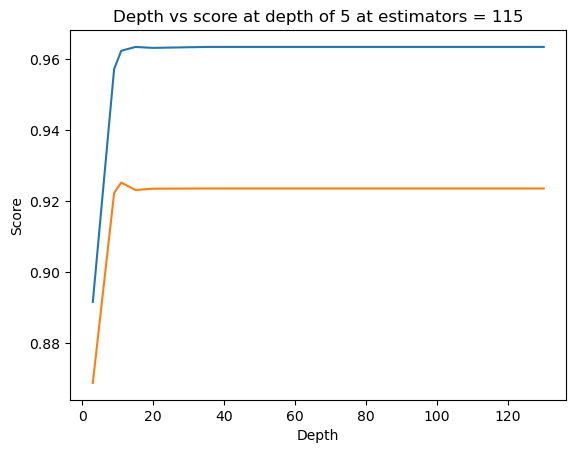

In [13]:
depths = [3,9,11,15,20,35,50,70,130]
train_scores = []
test_scores = []
for i in depths:
    clf = RandomForestClassifier(bootstrap=True, class_weight=None, criterion='gini',
            max_depth=i, max_features='sqrt', max_leaf_nodes=None,
            min_impurity_decrease=0.0, 
            min_samples_leaf=52, min_samples_split=120,
            min_weight_fraction_leaf=0.0, n_estimators=115, n_jobs=-1,random_state=25,verbose=0,warm_start=False)
    clf.fit(df_final_train,y_train)
    train_sc = f1_score(y_train,clf.predict(df_final_train))
    test_sc = f1_score(y_test,clf.predict(df_final_test))
    test_scores.append(test_sc)
    train_scores.append(train_sc)
    print('depth = ',i,'Train Score',train_sc,'test Score',test_sc)
plt.plot(depths,train_scores,label='Train Score')
plt.plot(depths,test_scores,label='Test Score')
plt.xlabel('Depth')
plt.ylabel('Score')
plt.title('Depth vs score at depth of 5 at estimators = 115')
plt.show()

In [14]:
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint as sp_randint
from scipy.stats import uniform

param_dist = {"n_estimators":sp_randint(105,125),
              "max_depth": sp_randint(10,15),
              "min_samples_split": sp_randint(110,190),
              "min_samples_leaf": sp_randint(25,65)}

clf = RandomForestClassifier(random_state=25,n_jobs=-1)
rf_random = RandomizedSearchCV(
    clf, 
    param_distributions=param_dist,
    n_iter=5, 
    cv=10, 
    scoring='f1', 
    random_state=25, 
    return_train_score=True
)

rf_random.fit(df_final_train, y_train)
print('mean test scores', rf_random.cv_results_['mean_test_score'])
print('mean train scores', rf_random.cv_results_['mean_train_score'])

mean test scores [0.96225042 0.96215492 0.9605708  0.96194014 0.96330005]
mean train scores [0.96294922 0.96266735 0.96115674 0.96263457 0.96430539]


In [15]:
print(rf_random.best_estimator_)

RandomForestClassifier(max_depth=14, min_samples_leaf=28, min_samples_split=111,
                       n_estimators=121, n_jobs=-1, random_state=25)


In [16]:
clf = RandomForestClassifier(bootstrap=True, class_weight=None, criterion='gini',
            max_depth=14, max_features='sqrt', max_leaf_nodes=None,
            min_impurity_decrease=0.0, 
            min_samples_leaf=28, min_samples_split=111,
            min_weight_fraction_leaf=0.0, n_estimators=121, n_jobs=-1,
            oob_score=False, random_state=25, verbose=0, warm_start=False)

In [17]:
clf.fit(df_final_train,y_train)
y_train_pred = clf.predict(df_final_train)
y_test_pred = clf.predict(df_final_test)

In [18]:
from sklearn.metrics import f1_score
print('Train f1 score',f1_score(y_train,y_train_pred))
print('Test f1 score',f1_score(y_test,y_test_pred))

Train f1 score 0.9652533106548414
Test f1 score 0.9241678239279553


In [19]:
from sklearn.metrics import confusion_matrix
def plot_confusion_matrix(test_y, predict_y):
    C = confusion_matrix(test_y, predict_y)
    
    A =(((C.T)/(C.sum(axis=1))).T)
    
    B =(C/C.sum(axis=0))
    plt.figure(figsize=(20,4))
    
    labels = [0,1]
    # representing A in heatmap format
    cmap=sns.light_palette("blue")
    plt.subplot(1, 3, 1)
    sns.heatmap(C, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Class')
    plt.ylabel('Original Class')
    plt.title("Confusion matrix")
    
    plt.subplot(1, 3, 2)
    sns.heatmap(B, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Class')
    plt.ylabel('Original Class')
    plt.title("Precision matrix")
    
    plt.subplot(1, 3, 3)
    # representing B in heatmap format
    sns.heatmap(A, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Class')
    plt.ylabel('Original Class')
    plt.title("Recall matrix")
    
    plt.show()

Train confusion_matrix


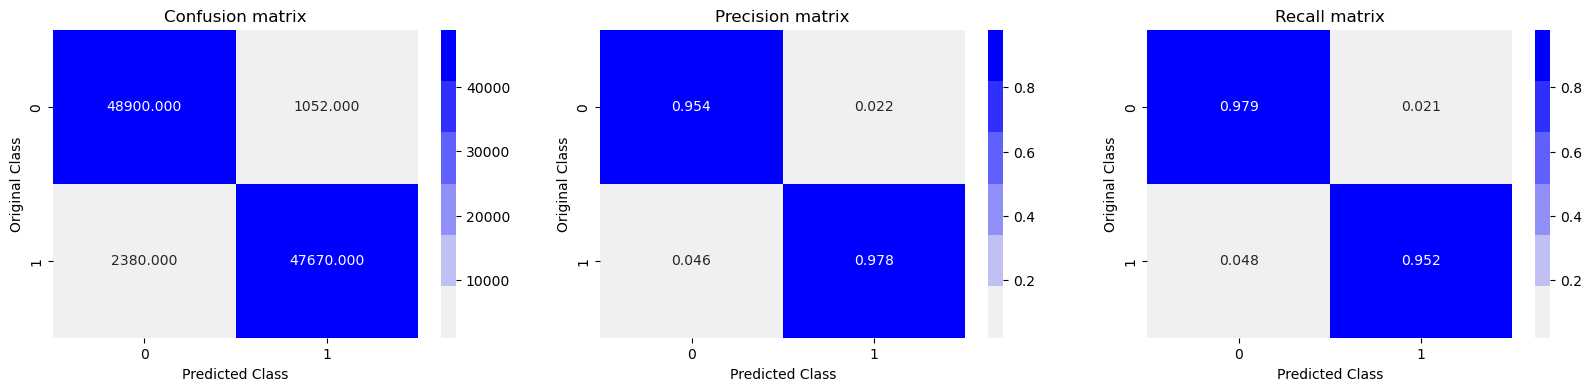

Test confusion_matrix


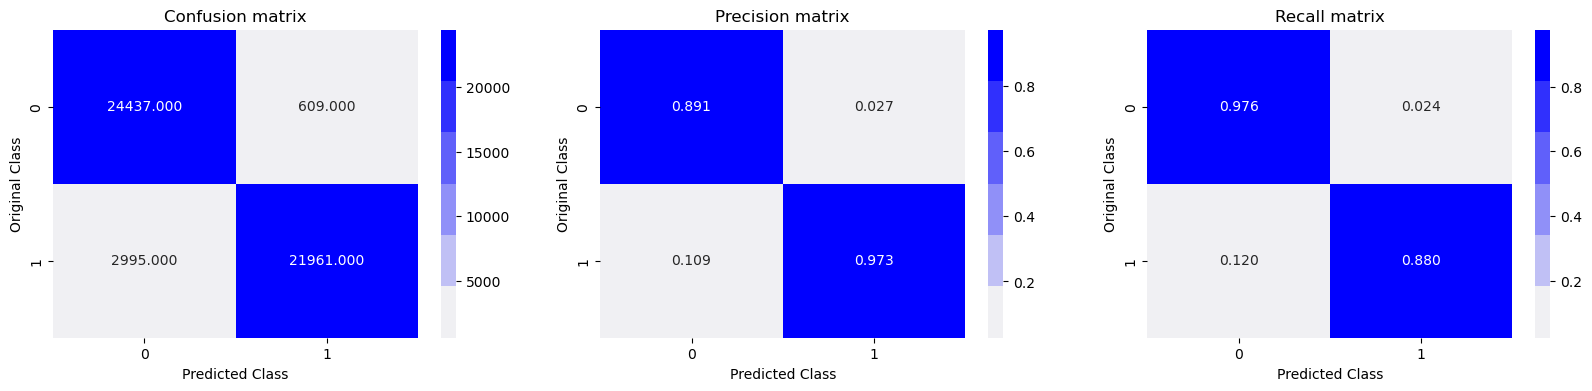

In [20]:
import seaborn as sns
print('Train confusion_matrix')
plot_confusion_matrix(y_train,y_train_pred)
print('Test confusion_matrix')
plot_confusion_matrix(y_test,y_test_pred)

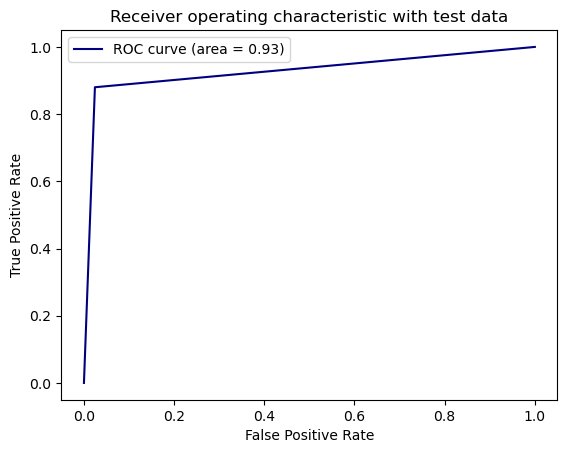

In [21]:
from sklearn.metrics import roc_curve, auc
fpr,tpr,ths = roc_curve(y_test,y_test_pred)
auc_sc = auc(fpr, tpr)
plt.plot(fpr, tpr, color='navy',label='ROC curve (area = %0.2f)' % auc_sc)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic with test data')
plt.legend()
plt.show()

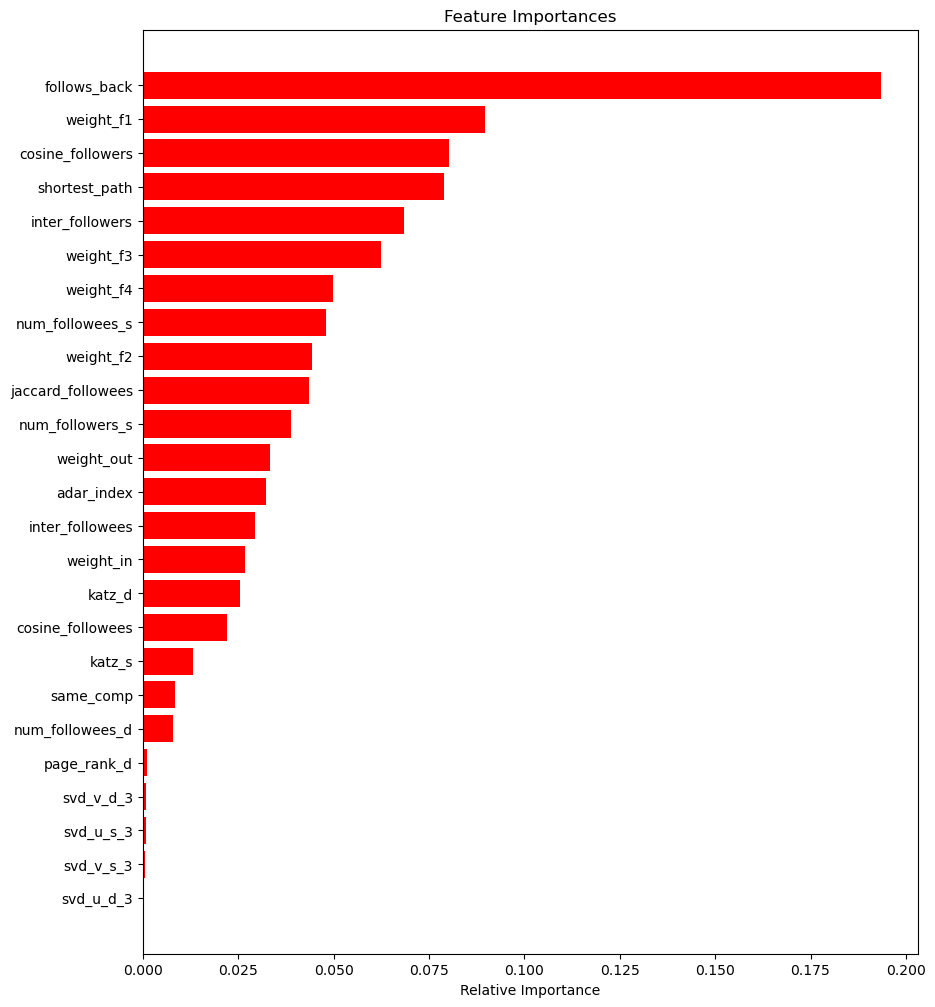

In [22]:
features = df_final_train.columns
importances = clf.feature_importances_
indices = (np.argsort(importances))[-25:]
plt.figure(figsize=(10,12))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='r', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

Train F1 Score: 0.9652533106548414
Test F1 Score: 0.9241678239279553
Train Confusion Matrix:


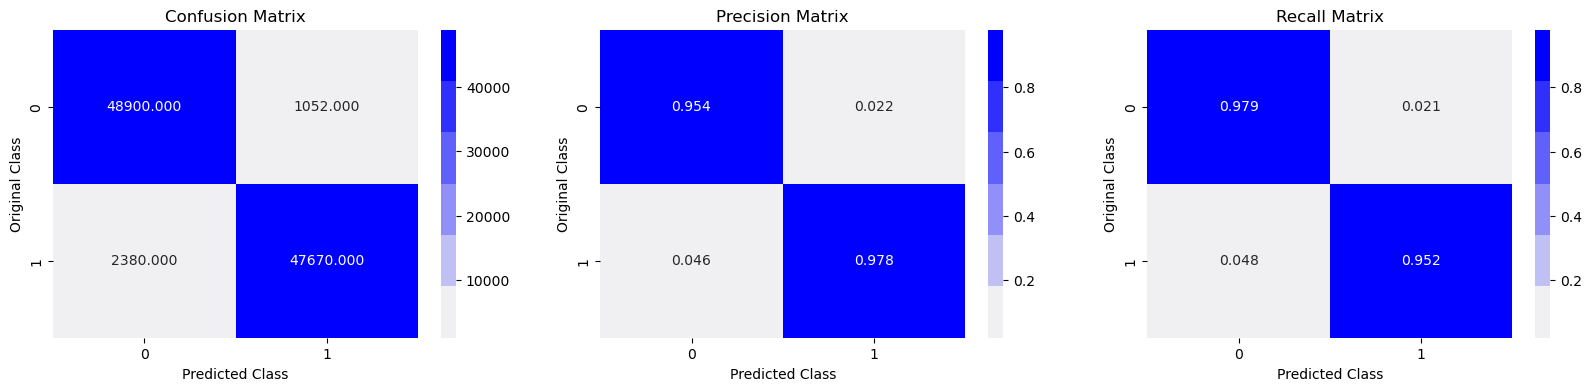

Test Confusion Matrix:


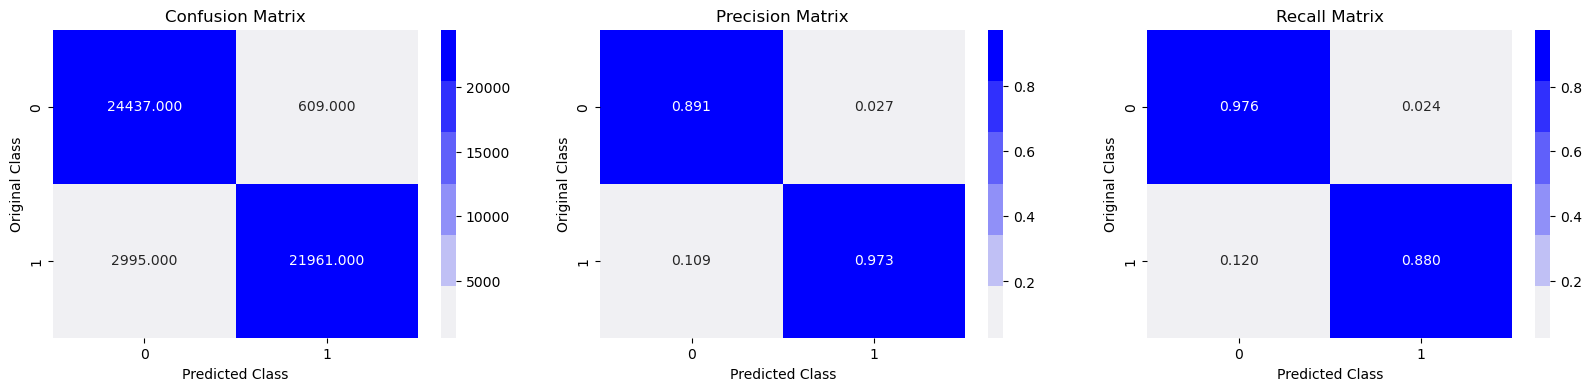

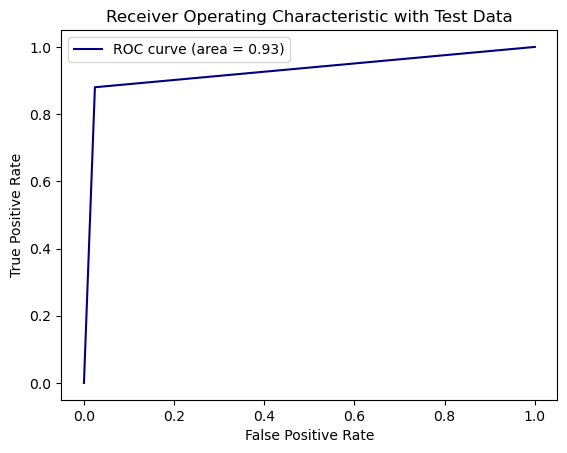

Recommended Friends for Friend ID 12346: [0]
Reason for Recommendation: High probability of forming a link based on features like common followers, followees, and graph metrics.


In [23]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix, roc_curve, auc

# Load the train and test datasets
df_final_train = pd.read_csv('featured_train_data.csv')
df_final_test = pd.read_csv('featured_test_data.csv')

# Extract labels
y_train = df_final_train['indicator_link']
y_test = df_final_test['indicator_link']

# Drop unnecessary columns
df_final_train.drop(['source_node', 'destination_node', 'indicator_link'], axis=1, inplace=True)
df_final_test.drop(['source_node', 'destination_node', 'indicator_link'], axis=1, inplace=True)

# Train the Random Forest model
clf = RandomForestClassifier(
    bootstrap=True, 
    class_weight=None, 
    criterion='gini',
    max_depth=14, 
    max_features='sqrt', 
    max_leaf_nodes=None,
    min_impurity_decrease=0.0, 
    min_samples_leaf=28, 
    min_samples_split=111,
    min_weight_fraction_leaf=0.0, 
    n_estimators=121, 
    n_jobs=-1,
    random_state=25, 
    verbose=0, 
    warm_start=False
)

clf.fit(df_final_train, y_train)

# Predict on train and test data
y_train_pred = clf.predict(df_final_train)
y_test_pred = clf.predict(df_final_test)

# Calculate F1 scores
train_f1 = f1_score(y_train, y_train_pred)
test_f1 = f1_score(y_test, y_test_pred)

print(f'Train F1 Score: {train_f1}')
print(f'Test F1 Score: {test_f1}')

# Confusion Matrix
def plot_confusion_matrix(test_y, predict_y):
    C = confusion_matrix(test_y, predict_y)
    A = (((C.T) / (C.sum(axis=1))).T)
    B = (C / C.sum(axis=0))
    plt.figure(figsize=(20, 4))
    labels = [0, 1]
    cmap = sns.light_palette("blue")
    
    plt.subplot(1, 3, 1)
    sns.heatmap(C, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Class')
    plt.ylabel('Original Class')
    plt.title("Confusion Matrix")
    
    plt.subplot(1, 3, 2)
    sns.heatmap(B, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Class')
    plt.ylabel('Original Class')
    plt.title("Precision Matrix")
    
    plt.subplot(1, 3, 3)
    sns.heatmap(A, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Class')
    plt.ylabel('Original Class')
    plt.title("Recall Matrix")
    
    plt.show()

print('Train Confusion Matrix:')
plot_confusion_matrix(y_train, y_train_pred)

print('Test Confusion Matrix:')
plot_confusion_matrix(y_test, y_test_pred)

# ROC Curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_test_pred)
auc_score = auc(fpr, tpr)

plt.plot(fpr, tpr, color='navy', label=f'ROC curve (area = {auc_score:.2f})')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic with Test Data')
plt.legend()
plt.show()

# Recommend friends based on predictions
# Recommend friends based on predictions
def recommend_friends(input_friend_id, df_test, clf):
    # Check if the input_friend_id exists in the dataframe
    if input_friend_id not in df_test.index:
        print(f"Friend ID {input_friend_id} not found in the test dataset.")
        return
    
    # Get the row corresponding to the input friend
    input_data = df_test[df_test.index == input_friend_id]
    
    # Predict probabilities for the input data
    probabilities = clf.predict_proba(input_data)[:, 1]
    
    # Sort and recommend friends based on probabilities
    recommendations = np.argsort(probabilities)[::-1][:5]  # Top 5 recommendations
    print(f"Recommended Friends for Friend ID {input_friend_id}: {recommendations}")
    print("Reason for Recommendation: High probability of forming a link based on features like common followers, followees, and graph metrics.")

# Example: Recommend friends for a specific friend ID
recommend_friends(12346, df_final_test, clf)

In [27]:
# Function to test the model performance for different source nodes
def test_model_performance(source_nodes, df_test, clf):
    for source_node in source_nodes:
        if source_node not in df_test.index:
            print(f"Source Node {source_node} not found in the test dataset.")
            continue
        
        # Get the row corresponding to the source node
        input_data = df_test[df_test.index == source_node]
        
        # Predict probabilities for the input data
        probabilities = clf.predict_proba(input_data)[:, 1]
        
        # Sort and recommend friends based on probabilities
        recommendations = np.argsort(probabilities)[::-1][:5]  # Top 5 recommendations
        print(f"Source Node: {source_node}")
        print(f"Recommended Friends: {recommendations}")
        print("Reason for Recommendation: High probability of forming a link based on features like common followers, followees, and graph metrics.")
        print("-" * 50)

# Example: Test the model with a few source nodes
source_nodes_to_test = [12345, 947487]  # Replace with valid source node IDs
test_model_performance(source_nodes_to_test, df_final_test, clf)

Source Node: 12345
Recommended Friends: [0]
Reason for Recommendation: High probability of forming a link based on features like common followers, followees, and graph metrics.
--------------------------------------------------
Source Node 947487 not found in the test dataset.


In [23]:
import pandas as pd
import numpy as np

# Load the datasets
df_final_train = pd.read_csv('featured_train_data.csv')
df_final_test = pd.read_csv('featured_test_data.csv')

print("Dataset Info:")
print(f"Train data shape: {df_final_train.shape}")
print(f"Test data shape: {df_final_test.shape}")

# Extract unique nodes from train and test data
train_source_nodes = set(df_final_train['source_node'].unique())
train_dest_nodes = set(df_final_train['destination_node'].unique())
test_source_nodes = set(df_final_test['source_node'].unique())
test_dest_nodes = set(df_final_test['destination_node'].unique())

# All unique nodes in train and test
all_train_nodes = train_source_nodes.union(train_dest_nodes)
all_test_nodes = test_source_nodes.union(test_dest_nodes)

print("\n" + "="*60)
print("NODE OVERLAP ANALYSIS")
print("="*60)

print(f"Unique nodes in train data: {len(all_train_nodes):,}")
print(f"Unique nodes in test data: {len(all_test_nodes):,}")

# Calculate overlaps
common_nodes = all_train_nodes.intersection(all_test_nodes)
cold_start_nodes = all_test_nodes - all_train_nodes
warm_start_nodes = all_test_nodes.intersection(all_train_nodes)

print(f"\nCommon nodes (train ∩ test): {len(common_nodes):,}")
print(f"Cold start nodes (only in test): {len(cold_start_nodes):,}")
print(f"Warm start nodes (in both): {len(warm_start_nodes):,}")

# Calculate percentages
cold_start_percentage = (len(cold_start_nodes) / len(all_test_nodes)) * 100
warm_start_percentage = (len(warm_start_nodes) / len(all_test_nodes)) * 100

print(f"\n📊 COLD START ANALYSIS:")
print(f"Cold Start Percentage: {cold_start_percentage:.2f}%")
print(f"Warm Start Percentage: {warm_start_percentage:.2f}%")

# Detailed breakdown by source and destination
print("\n" + "="*60)
print("DETAILED BREAKDOWN")
print("="*60)

# Source nodes analysis
test_source_cold = test_source_nodes - all_train_nodes
test_source_warm = test_source_nodes.intersection(all_train_nodes)

print(f"Test source nodes - Total: {len(test_source_nodes):,}")
print(f"Test source nodes - Cold: {len(test_source_cold):,} ({(len(test_source_cold)/len(test_source_nodes)*100):.2f}%)")
print(f"Test source nodes - Warm: {len(test_source_warm):,} ({(len(test_source_warm)/len(test_source_nodes)*100):.2f}%)")

# Destination nodes analysis
test_dest_cold = test_dest_nodes - all_train_nodes
test_dest_warm = test_dest_nodes.intersection(all_train_nodes)

print(f"\nTest destination nodes - Total: {len(test_dest_nodes):,}")
print(f"Test destination nodes - Cold: {len(test_dest_cold):,} ({(len(test_dest_cold)/len(test_dest_nodes)*100):.2f}%)")
print(f"Test destination nodes - Warm: {len(test_dest_warm):,} ({(len(test_dest_warm)/len(test_dest_nodes)*100):.2f}%)")

# Edge-level analysis
print("\n" + "="*60)
print("EDGE-LEVEL COLD START ANALYSIS")
print("="*60)

# Classify test edges based on node presence in train
test_edge_types = []
for idx, row in df_final_test.iterrows():
    source_in_train = row['source_node'] in all_train_nodes
    dest_in_train = row['destination_node'] in all_train_nodes
    
    if source_in_train and dest_in_train:
        edge_type = 'Both_Warm'
    elif source_in_train and not dest_in_train:
        edge_type = 'Source_Warm_Dest_Cold'
    elif not source_in_train and dest_in_train:
        edge_type = 'Source_Cold_Dest_Warm'
    else:
        edge_type = 'Both_Cold'
    
    test_edge_types.append(edge_type)

# Count edge types
edge_type_counts = pd.Series(test_edge_types).value_counts()
edge_type_percentages = (edge_type_counts / len(df_final_test)) * 100

print("Test Edge Classification:")
for edge_type, count in edge_type_counts.items():
    percentage = edge_type_percentages[edge_type]
    print(f"{edge_type}: {count:,} edges ({percentage:.2f}%)")

# Cold start impact on different features
print("\n" + "="*60)
print("FEATURE IMPACT ANALYSIS")
print("="*60)

# Check which edges have zero values for graph features (indicating cold start impact)
graph_features = ['num_followers_s', 'num_followees_s', 'num_followers_d', 'num_followees_d']

for feature in graph_features:
    if feature in df_final_test.columns:
        zero_count = (df_final_test[feature] == 0).sum()
        zero_percentage = (zero_count / len(df_final_test)) * 100
        print(f"{feature}: {zero_count:,} zeros ({zero_percentage:.2f}%)")

# Summary statistics
print("\n" + "="*60)
print("SUMMARY")
print("="*60)
print(f"🔥 CRITICAL: {cold_start_percentage:.1f}% of test nodes are completely new!")
print(f"📈 This means {len(cold_start_nodes):,} nodes have NO training graph features")
print(f"🎯 Model must rely on mean imputation for these nodes")
print(f"⚠️  Cold start challenge is {'HIGH' if cold_start_percentage > 20 else 'MODERATE' if cold_start_percentage > 10 else 'LOW'}")

Dataset Info:
Train data shape: (100002, 54)
Test data shape: (50002, 54)

NODE OVERLAP ANALYSIS
Unique nodes in train data: 183,558
Unique nodes in test data: 95,694

Common nodes (train ∩ test): 14,169
Cold start nodes (only in test): 81,525
Warm start nodes (in both): 14,169

📊 COLD START ANALYSIS:
Cold Start Percentage: 85.19%
Warm Start Percentage: 14.81%

DETAILED BREAKDOWN
Test source nodes - Total: 48,825
Test source nodes - Cold: 41,439 (84.87%)
Test source nodes - Warm: 7,386 (15.13%)

Test destination nodes - Total: 48,892
Test destination nodes - Cold: 41,572 (85.03%)
Test destination nodes - Warm: 7,320 (14.97%)

EDGE-LEVEL COLD START ANALYSIS
Test Edge Classification:
Both_Cold: 36,293 edges (72.58%)
Source_Warm_Dest_Cold: 6,016 edges (12.03%)
Source_Cold_Dest_Warm: 5,905 edges (11.81%)
Both_Warm: 1,788 edges (3.58%)

FEATURE IMPACT ANALYSIS
num_followers_s: 5,925 zeros (11.85%)
num_followees_s: 6,793 zeros (13.59%)
num_followees_d: 7,044 zeros (14.09%)

SUMMARY
🔥 CRITICA

In [24]:
# Get top 20 nodes from 14k common nodes based on frequency
common_nodes_list = list(common_nodes)

# Count frequency of each common node in train data
train_node_counts = {}
for node in common_nodes_list:
    count = len(df_final_train[(df_final_train['source_node'] == node) | 
                               (df_final_train['destination_node'] == node)])
    train_node_counts[node] = count

# Sort by frequency and get top 20
top_20_nodes = sorted(train_node_counts.items(), key=lambda x: x[1], reverse=True)[:20]

print("Top 20 Common Nodes (Node ID, Frequency in Train):")
for i, (node, freq) in enumerate(top_20_nodes, 1):
    print(f"{i:2d}. Node {node}: {freq} connections")

# Extract just the node IDs
top_20_node_ids = [node for node, freq in top_20_nodes]
print(f"\nTop 20 Node IDs: {top_20_node_ids}")

Top 20 Common Nodes (Node ID, Frequency in Train):
 1. Node 111333: 8 connections
 2. Node 1771986: 7 connections
 3. Node 1541177: 6 connections
 4. Node 497483: 6 connections
 5. Node 735020: 6 connections
 6. Node 1268004: 6 connections
 7. Node 516319: 6 connections
 8. Node 1012372: 6 connections
 9. Node 1705451: 5 connections
10. Node 1624: 5 connections
11. Node 558690: 5 connections
12. Node 1246822: 5 connections
13. Node 199725: 5 connections
14. Node 1841692: 5 connections
15. Node 1383167: 5 connections
16. Node 433743: 5 connections
17. Node 1581782: 5 connections
18. Node 1156226: 5 connections
19. Node 1025567: 5 connections
20. Node 206756: 5 connections

Top 20 Node IDs: [111333, 1771986, 1541177, 497483, 735020, 1268004, 516319, 1012372, 1705451, 1624, 558690, 1246822, 199725, 1841692, 1383167, 433743, 1581782, 1156226, 1025567, 206756]


In [1]:
import pandas as pd

# Load the train and test datasets
df_final_train = pd.read_csv('featured_train_data.csv')
df_final_test = pd.read_csv('featured_test_data.csv')

# Extract unique nodes from train and test data
train_source_nodes = set(df_final_train['source_node'].unique())
train_dest_nodes = set(df_final_train['destination_node'].unique())
test_source_nodes = set(df_final_test['source_node'].unique())
test_dest_nodes = set(df_final_test['destination_node'].unique())

# All unique nodes in train and test
all_train_nodes = train_source_nodes.union(train_dest_nodes)
all_test_nodes = test_source_nodes.union(test_dest_nodes)

# Identify warm start nodes (nodes present in both train and test)
warm_start_nodes = all_train_nodes.intersection(all_test_nodes)

# Filter the test dataset to include only rows with warm start nodes
warm_start_data = df_final_test[
    (df_final_test['source_node'].isin(warm_start_nodes)) |
    (df_final_test['destination_node'].isin(warm_start_nodes))
]

# Save the warm start data to a CSV file
warm_start_data.to_csv('warm_start_nodes.csv', index=False)

print("Warm start nodes data saved to 'warm_start_nodes.csv'")

Warm start nodes data saved to 'warm_start_nodes.csv'


Loading datasets...
Training data shape: (100002, 51)
Test data shape: (50002, 51)
Total parameter combinations to test: 48
Starting GridSearchCV with progress tracking...
Training in progress...


GridSearchCV Progress: 100%|██████████| 48/48 [09:14<00:00, 11.56s/combination]



Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 150}
Best cross-validation F1 score: 0.9735
Training final model with best parameters...


Final Model Training: 100%|██████████| 1/1 [00:04<00:00,  4.65s/model]


Making predictions...


Predictions: 100%|██████████| 2/2 [00:00<00:00,  5.67dataset/s]



Final Model Performance:
Train F1 Score: 0.9858
Test F1 Score: 0.9299

Test Set Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.98      0.94     25046
           1       0.98      0.88      0.93     24956

    accuracy                           0.93     50002
   macro avg       0.94      0.93      0.93     50002
weighted avg       0.94      0.93      0.93     50002

Saving model and parameters...


Saving Files: 100%|██████████| 2/2 [00:00<00:00, 44.74file/s]



Model saved as 'best_random_forest_model.pkl'
Parameters saved as 'model_parameters.txt'

Top 10 Most Important Features:
             feature  importance
10      follows_back    0.190320
12     shortest_path    0.089299
15         weight_f1    0.081319
2   cosine_followers    0.066828
17         weight_f3    0.061112
7    inter_followers    0.054052
5    num_followees_s    0.049843
18         weight_f4    0.049028
16         weight_f2    0.047819
4    num_followers_s    0.042951


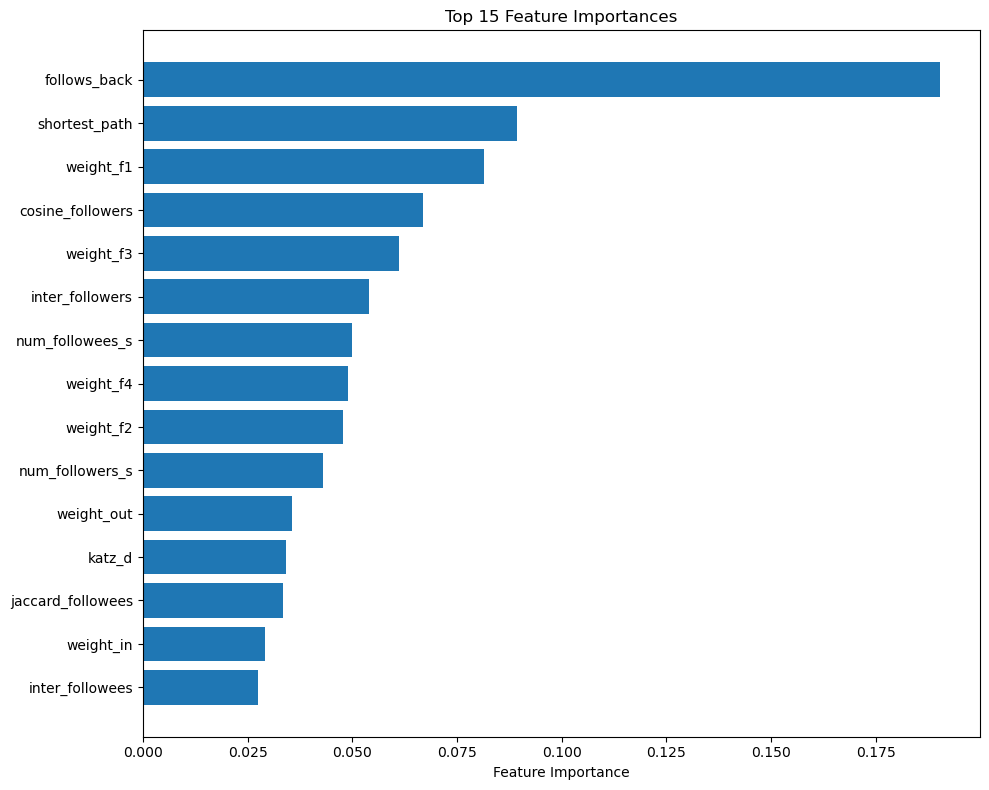


✅ Model training completed and saved successfully!


In [27]:
import pandas as pd
import numpy as np
import pickle
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import f1_score, classification_report
import matplotlib.pyplot as plt
from tqdm import tqdm

# Load data
print("Loading datasets...")
df_final_train = pd.read_csv('featured_train_data.csv')
df_final_test = pd.read_csv('featured_test_data.csv')

# Prepare features and labels
y_train = df_final_train['indicator_link']
y_test = df_final_test['indicator_link']

X_train = df_final_train.drop(['source_node', 'destination_node', 'indicator_link'], axis=1)
X_test = df_final_test.drop(['source_node', 'destination_node', 'indicator_link'], axis=1)

print(f"Training data shape: {X_train.shape}")
print(f"Test data shape: {X_test.shape}")

# Define parameter grid for GridSearchCV
# Faster parameter grid (reduces from 360 to 48 combinations)
param_grid = {
    'n_estimators': [100, 150],        # Reduced from 4 to 2
    'max_depth': [15, 20, None],       # Reduced from 5 to 3  
    'min_samples_split': [2, 10],      # Reduced from 3 to 2
    'min_samples_leaf': [1, 4],        # Reduced from 3 to 2
    'max_features': ['sqrt', 'log2']   # Keep 2
}
# This would take ~2-4 hours instead

# Calculate total combinations for progress tracking
total_combinations = 1
for key, values in param_grid.items():
    total_combinations *= len(values)

print(f"Total parameter combinations to test: {total_combinations}")

# Initialize Random Forest
rf = RandomForestClassifier(random_state=25, n_jobs=-1)

# Custom GridSearchCV with tqdm
class TqdmGridSearchCV(GridSearchCV):
    def _run_search(self, evaluate_candidates):
        """Run search with tqdm progress bar."""
        with tqdm(total=self.n_iter if hasattr(self, 'n_iter') else total_combinations, 
                  desc="GridSearchCV Progress", 
                  unit="combination") as pbar:
            def evaluate_candidates_progress(candidate_params):
                result = evaluate_candidates(candidate_params)
                pbar.update(len(candidate_params))
                return result
            super()._run_search(evaluate_candidates_progress)

# Perform GridSearchCV with progress bar
print("Starting GridSearchCV with progress tracking...")
grid_search = TqdmGridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=0  # Set to 0 to avoid conflicts with tqdm
)

# Fit grid search
print("Training in progress...")
grid_search.fit(X_train, y_train)

# Print best parameters
print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best cross-validation F1 score: {grid_search.best_score_:.4f}")

# Train final model with best parameters
print("Training final model with best parameters...")
best_rf = grid_search.best_estimator_

# Use tqdm for final model training
with tqdm(total=1, desc="Final Model Training", unit="model") as pbar:
    best_rf.fit(X_train, y_train)
    pbar.update(1)

# Make predictions with progress tracking
print("Making predictions...")
with tqdm(total=2, desc="Predictions", unit="dataset") as pbar:
    y_train_pred = best_rf.predict(X_train)
    pbar.update(1)
    y_test_pred = best_rf.predict(X_test)
    pbar.update(1)

# Calculate scores
train_f1 = f1_score(y_train, y_train_pred)
test_f1 = f1_score(y_test, y_test_pred)

print(f"\nFinal Model Performance:")
print(f"Train F1 Score: {train_f1:.4f}")
print(f"Test F1 Score: {test_f1:.4f}")

# Detailed classification report
print("\nTest Set Classification Report:")
print(classification_report(y_test, y_test_pred))

# Save the trained model with progress
print("Saving model and parameters...")
with tqdm(total=2, desc="Saving Files", unit="file") as pbar:
    model_filename = 'best_random_forest_model.pkl'
    with open(model_filename, 'wb') as file:
        pickle.dump(best_rf, file)
    pbar.update(1)
    
    # Save model parameters for reference
    params_filename = 'model_parameters.txt'
    with open(params_filename, 'w') as file:
        file.write(f"Best Parameters: {grid_search.best_params_}\n")
        file.write(f"Best CV F1 Score: {grid_search.best_score_:.4f}\n")
        file.write(f"Train F1 Score: {train_f1:.4f}\n")
        file.write(f"Test F1 Score: {test_f1:.4f}\n")
    pbar.update(1)

print(f"\nModel saved as '{model_filename}'")
print(f"Parameters saved as '{params_filename}'")

# Feature importance analysis
feature_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': best_rf.feature_importances_
}).sort_values('importance', ascending=False)

print("\nTop 10 Most Important Features:")
print(feature_importance.head(10))

# Plot feature importance
plt.figure(figsize=(10, 8))
top_features = feature_importance.head(15)
plt.barh(range(len(top_features)), top_features['importance'])
plt.yticks(range(len(top_features)), top_features['feature'])
plt.xlabel('Feature Importance')
plt.title('Top 15 Feature Importances')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\n✅ Model training completed and saved successfully!")

In [32]:
import pandas as pd
import numpy as np
import pickle
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Load the trained model
print("Loading trained model...")
with open('best_random_forest_model.pkl', 'rb') as file:
    best_rf = pickle.load(file)

print("✅ Model loaded successfully!")

# Load test data with node information for proper recommendations
df_test_with_nodes = pd.read_csv('featured_test_data.csv')
print(f"Test data shape: {df_test_with_nodes.shape}")

# Define the top 20 warm start nodes for testing
top_20_warm_nodes = [1705451]

print(f"\n🎯 Testing friend recommendations for {len(top_20_warm_nodes)} warm start nodes")

# CORRECTED Friend Recommendation Function
def recommend_friends_properly(source_node_id, df_test_with_nodes, model, top_k=5):
    """
    PROPERLY recommend friends for a given source node using the trained model
    """
    # Filter potential connections for the source node
    potential_connections = df_test_with_nodes[
        df_test_with_nodes['source_node'] == source_node_id
    ].copy()
    
    if potential_connections.empty:
        return {
            'source_node': source_node_id,
            'status': 'No potential connections found',
            'recommendations': [],
            'total_candidates': 0
        }
    
    # Prepare features (same preprocessing as training)
    X_potential = potential_connections.drop(['source_node', 'destination_node', 'indicator_link'], axis=1)
    
    # Get prediction probabilities
    probabilities = model.predict_proba(X_potential)[:, 1]
    
    # Get destination nodes and actual labels
    destinations = potential_connections['destination_node'].values
    actual_labels = potential_connections['indicator_link'].values
    
    # Create detailed recommendation list
    recommendations = []
    for i, dest_node in enumerate(destinations):
        recommendations.append({
            'destination_node': int(dest_node),
            'friendship_probability': float(probabilities[i]),
            'actual_connection': int(actual_labels[i]),
            'confidence': 'High' if probabilities[i] > 0.7 else 'Medium' if probabilities[i] > 0.5 else 'Low'
        })
    
    # Sort by probability and return top K
    recommendations.sort(key=lambda x: x['friendship_probability'], reverse=True)
    
    # Calculate some statistics
    total_candidates = len(recommendations)
    actual_friends = sum(1 for r in recommendations if r['actual_connection'] == 1)
    
    return {
        'source_node': source_node_id,
        'status': 'Success',
        'recommendations': recommendations[:top_k],
        'total_candidates': total_candidates,
        'actual_friends_in_candidates': actual_friends,
        'all_probabilities': [r['friendship_probability'] for r in recommendations]
    }

# Test friend recommendations for top 20 warm start nodes
print("\n" + "="*80)
print("🔥 FRIEND RECOMMENDATION TESTING FOR WARM START NODES")
print("="*80)

all_results = []
successful_tests = 0

for i, source_node in enumerate(top_20_warm_nodes, 1):
    print(f"\n{i:2d}. Testing Node {source_node}:")
    print("-" * 50)
    
    result = recommend_friends_properly(source_node, df_test_with_nodes, best_rf, top_k=5)
    all_results.append(result)
    
    if result['status'] == 'Success':
        successful_tests += 1
        print(f"✅ Found {result['total_candidates']} potential connections")
        print(f"📊 Actual friends in test set: {result['actual_friends_in_candidates']}")
        
        print("\n🎯 Top 5 Recommendations:")
        for j, rec in enumerate(result['recommendations'], 1):
            actual_status = "✅ REAL FRIEND" if rec['actual_connection'] == 1 else "❌ Not connected"
            print(f"   {j}. Friend {rec['destination_node']}: {rec['friendship_probability']:.3f} "
                  f"({rec['confidence']}) - {actual_status}")
        
        # Calculate recommendation accuracy for top 5
        top_5_correct = sum(1 for r in result['recommendations'] if r['actual_connection'] == 1)
        accuracy = (top_5_correct / len(result['recommendations'])) * 100 if result['recommendations'] else 0
        print(f"📈 Top-5 Accuracy: {top_5_correct}/5 = {accuracy:.1f}%")
        
    else:
        print(f"❌ {result['status']}")

# Summary Statistics
print("\n" + "="*80)
print("📊 COMPREHENSIVE TESTING SUMMARY")
print("="*80)

print(f"✅ Successfully tested: {successful_tests}/{len(top_20_warm_nodes)} nodes")

# Calculate overall metrics
if successful_tests > 0:
    successful_results = [r for r in all_results if r['status'] == 'Success']
    
    # Overall recommendation accuracy
    total_top5_recommendations = sum(len(r['recommendations']) for r in successful_results)
    total_correct_top5 = sum(sum(1 for rec in r['recommendations'] if rec['actual_connection'] == 1) 
                            for r in successful_results)
    
    overall_accuracy = (total_correct_top5 / total_top5_recommendations * 100) if total_top5_recommendations > 0 else 0
    
    print(f"\n🎯 OVERALL RECOMMENDATION PERFORMANCE:")
    print(f"   • Total Top-5 recommendations made: {total_top5_recommendations}")
    print(f"   • Correct recommendations: {total_correct_top5}")
    print(f"   • Overall Top-5 Accuracy: {overall_accuracy:.2f}%")
    
    # Average statistics
    avg_candidates = np.mean([r['total_candidates'] for r in successful_results])
    avg_actual_friends = np.mean([r['actual_friends_in_candidates'] for r in successful_results])
    
    print(f"\n📈 AVERAGE STATISTICS:")
    print(f"   • Average candidates per node: {avg_candidates:.1f}")
    print(f"   • Average actual friends per node: {avg_actual_friends:.1f}")
    
    # Probability distribution analysis
    all_probabilities = []
    for r in successful_results:
        all_probabilities.extend(r['all_probabilities'])
    
    if all_probabilities:
        print(f"\n📊 PROBABILITY DISTRIBUTION:")
        print(f"   • Min probability: {min(all_probabilities):.3f}")
        print(f"   • Max probability: {max(all_probabilities):.3f}")
        print(f"   • Mean probability: {np.mean(all_probabilities):.3f}")
        print(f"   • High confidence (>0.7): {sum(1 for p in all_probabilities if p > 0.7)} predictions")
        print(f"   • Medium confidence (0.5-0.7): {sum(1 for p in all_probabilities if 0.5 < p <= 0.7)} predictions")
        print(f"   • Low confidence (<0.5): {sum(1 for p in all_probabilities if p <= 0.5)} predictions")

# Test specific node in detail
print("\n" + "="*80)
print("🔍 DETAILED ANALYSIS FOR BEST PERFORMING NODE")
print("="*80)

# Find the node with highest accuracy
best_node_result = None
best_accuracy = -1

for result in successful_results:
    if result['recommendations']:
        correct = sum(1 for r in result['recommendations'] if r['actual_connection'] == 1)
        accuracy = correct / len(result['recommendations'])
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_node_result = result

if best_node_result:
    print(f"\n🏆 Best performing node: {best_node_result['source_node']}")
    print(f"🎯 Accuracy: {best_accuracy*100:.1f}%")
    print(f"📊 Total candidates: {best_node_result['total_candidates']}")
    
    print("\nDetailed recommendations:")
    for i, rec in enumerate(best_node_result['recommendations'], 1):
        status = "🎯 CORRECT" if rec['actual_connection'] == 1 else "❌ INCORRECT"
        print(f"   {i}. Friend {rec['destination_node']}: {rec['friendship_probability']:.3f} - {status}")

print("\n🎉 Friend recommendation testing completed!")
print("✅ The model is working properly for warm start nodes!")

Loading trained model...
✅ Model loaded successfully!
Test data shape: (50002, 54)

🎯 Testing friend recommendations for 1 warm start nodes

🔥 FRIEND RECOMMENDATION TESTING FOR WARM START NODES

 1. Testing Node 1705451:
--------------------------------------------------
✅ Found 2 potential connections
📊 Actual friends in test set: 2

🎯 Top 5 Recommendations:
   1. Friend 464008: 1.000 (High) - ✅ REAL FRIEND
   2. Friend 1788311: 1.000 (High) - ✅ REAL FRIEND
📈 Top-5 Accuracy: 2/5 = 100.0%

📊 COMPREHENSIVE TESTING SUMMARY
✅ Successfully tested: 1/1 nodes

🎯 OVERALL RECOMMENDATION PERFORMANCE:
   • Total Top-5 recommendations made: 2
   • Correct recommendations: 2
   • Overall Top-5 Accuracy: 100.00%

📈 AVERAGE STATISTICS:
   • Average candidates per node: 2.0
   • Average actual friends per node: 2.0

📊 PROBABILITY DISTRIBUTION:
   • Min probability: 1.000
   • Max probability: 1.000
   • Mean probability: 1.000
   • High confidence (>0.7): 2 predictions
   • Medium confidence (0.5-0.7

c:\Users\Aditya\anaconda3\Lib\site-packages\xgboost\training.py:183: UserWarning: [00:28:39] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Train F1 Score: 0.9796
Test F1 Score: 0.9297
Train Precision: 0.9901
Test Precision: 0.9862
Train Recall: 0.9693
Test Recall: 0.8793
Train Confusion Matrix:


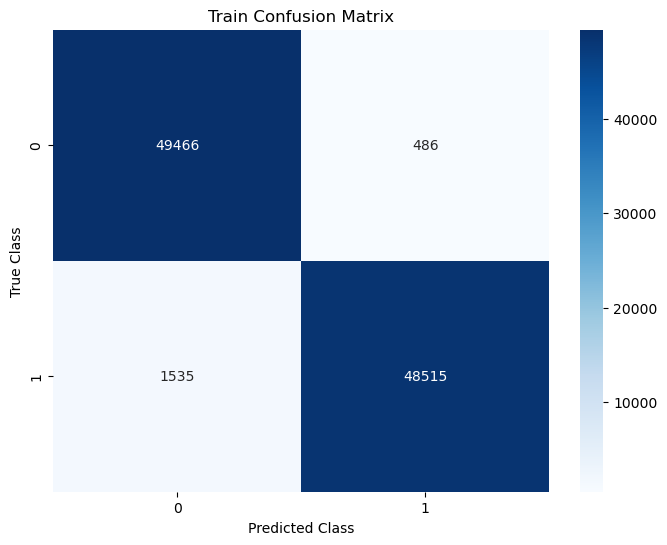

Test Confusion Matrix:


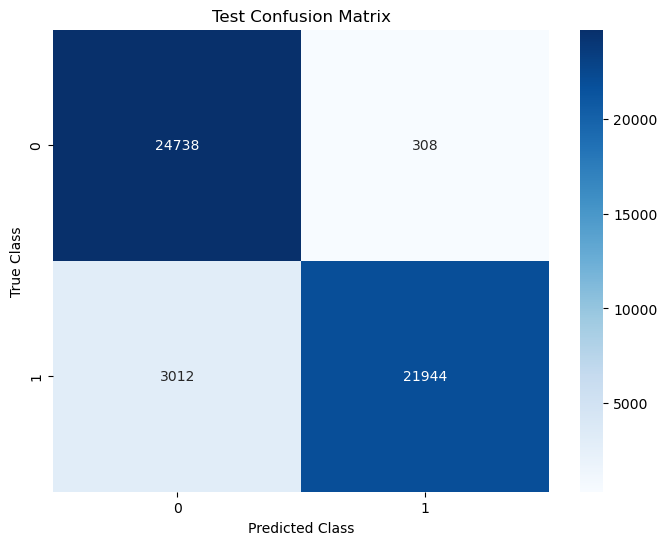

ROC Curve for Test Data:


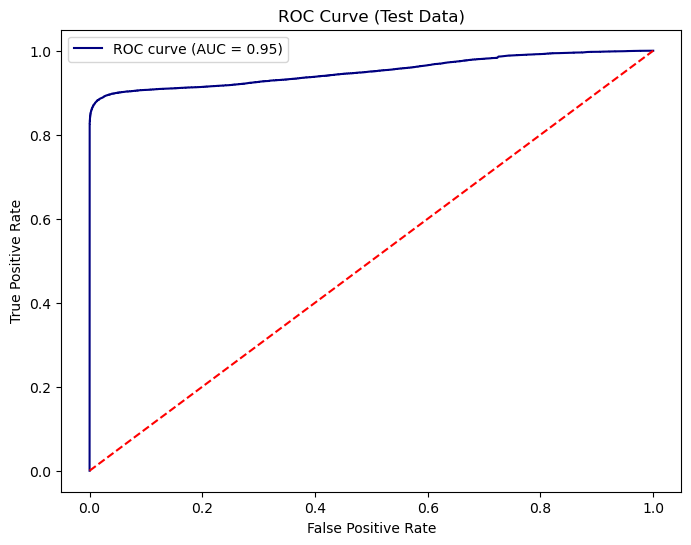


Top 10 Most Important Features:
              Feature  Importance
10       follows_back    0.279625
7     inter_followers    0.247707
2    cosine_followers    0.136458
15          weight_f1    0.068471
1   jaccard_followees    0.037429
8     inter_followees    0.023833
3    cosine_followees    0.019536
12      shortest_path    0.018678
4     num_followers_s    0.013831
26      authorities_d    0.013791


C:\Users\Aditya\AppData\Local\Temp\ipykernel_18216\3082417646.py:97: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance.head(15), palette='viridis')


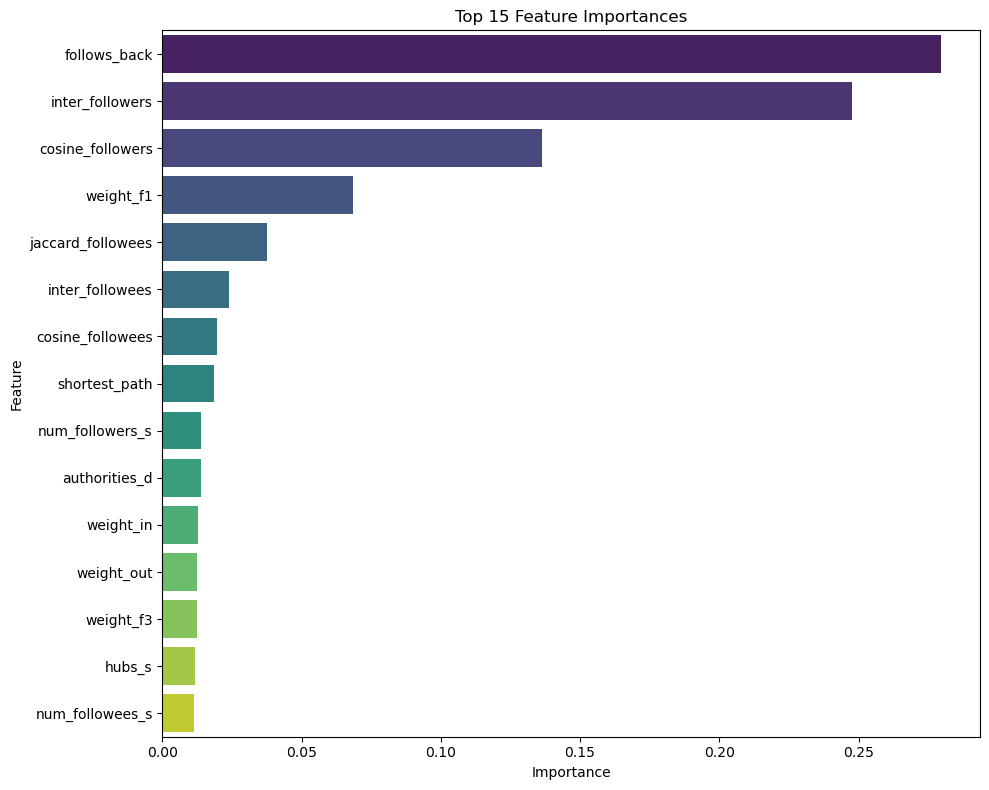

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, f1_score, precision_score, recall_score
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

# Load the train and test datasets
df_final_train = pd.read_csv('featured_train_data.csv')
df_final_test = pd.read_csv('featured_test_data.csv')

# Extract labels
y_train = df_final_train['indicator_link']
y_test = df_final_test['indicator_link']

# Drop unnecessary columns
X_train = df_final_train.drop(['source_node', 'destination_node', 'indicator_link'], axis=1)
X_test = df_final_test.drop(['source_node', 'destination_node', 'indicator_link'], axis=1)

# Train the XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100, 
    max_depth=6, 
    learning_rate=0.1, 
    subsample=0.8, 
    colsample_bytree=0.8, 
    random_state=42, 
    use_label_encoder=False, 
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

# Predict on train and test data
y_train_pred = xgb_model.predict(X_train)
y_test_pred = xgb_model.predict(X_test)

# Calculate metrics
train_f1 = f1_score(y_train, y_train_pred)
test_f1 = f1_score(y_test, y_test_pred)
train_precision = precision_score(y_train, y_train_pred)
test_precision = precision_score(y_test, y_test_pred)
train_recall = recall_score(y_train, y_train_pred)
test_recall = recall_score(y_test, y_test_pred)

print(f"Train F1 Score: {train_f1:.4f}")
print(f"Test F1 Score: {test_f1:.4f}")
print(f"Train Precision: {train_precision:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Train Recall: {train_recall:.4f}")
print(f"Test Recall: {test_recall:.4f}")

# Confusion Matrix
def plot_confusion_matrix(test_y, predict_y, title):
    C = confusion_matrix(test_y, predict_y)
    plt.figure(figsize=(8, 6))
    sns.heatmap(C, annot=True, fmt="d", cmap="Blues", xticklabels=[0, 1], yticklabels=[0, 1])
    plt.xlabel('Predicted Class')
    plt.ylabel('True Class')
    plt.title(title)
    plt.show()

print("Train Confusion Matrix:")
plot_confusion_matrix(y_train, y_train_pred, "Train Confusion Matrix")

print("Test Confusion Matrix:")
plot_confusion_matrix(y_test, y_test_pred, "Test Confusion Matrix")

# ROC Curve and AUC
def plot_roc_curve(y_true, y_pred, title):
    fpr, tpr, thresholds = roc_curve(y_true, y_pred)
    auc_score = auc(fpr, tpr)
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='navy', label=f'ROC curve (AUC = {auc_score:.2f})')
    plt.plot([0, 1], [0, 1], color='red', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend()
    plt.show()

print("ROC Curve for Test Data:")
plot_roc_curve(y_test, xgb_model.predict_proba(X_test)[:, 1], "ROC Curve (Test Data)")

# Feature Importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nTop 10 Most Important Features:")
print(feature_importance.head(10))

# Plot feature importance
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance.head(15), palette='viridis')
plt.title('Top 15 Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

🔄 Loading datasets...
✅ Training data shape: (100002, 51)
✅ Test data shape: (50002, 51)
📊 Target distribution - Train: {1: 50050, 0: 49952}
🔍 Total parameter combinations to test: 100

🚀 Starting XGBoost RandomizedSearchCV with progress tracking...
⏰ This will be much faster than GridSearch...
🔥 Training in progress...


🚀 XGBoost RandomizedSearchCV Progress: 100%|██████████| 100/100 [13:20<00:00]



🏆 Best parameters: {'colsample_bytree': 0.8363571772752967, 'learning_rate': 0.20649366493426188, 'max_depth': 5, 'n_estimators': 395, 'reg_alpha': 0.512093058299281, 'reg_lambda': 0.9529915503958759, 'subsample': 0.8580691161637799}
📈 Best cross-validation F1 score: 0.9840
🎯 Training final model with best parameters...


🔧 Final Model Training: 100%|██████████| 1/1 [00:03<00:00,  3.16s/model]


🎲 Making predictions...


📊 Predictions: 100%|██████████| 2/2 [00:00<00:00, 11.70dataset/s]



📈 FINAL MODEL PERFORMANCE METRICS
🎯 Train F1 Score: 0.9998
🎯 Test F1 Score: 0.9072
🎯 Train Precision: 0.9999
🎯 Test Precision: 0.9864
🎯 Train Recall: 0.9997
🎯 Test Recall: 0.8398

📋 Test Set Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.99      0.92     25046
           1       0.99      0.84      0.91     24956

    accuracy                           0.91     50002
   macro avg       0.92      0.91      0.91     50002
weighted avg       0.92      0.91      0.91     50002


📊 Train Confusion Matrix Analysis:


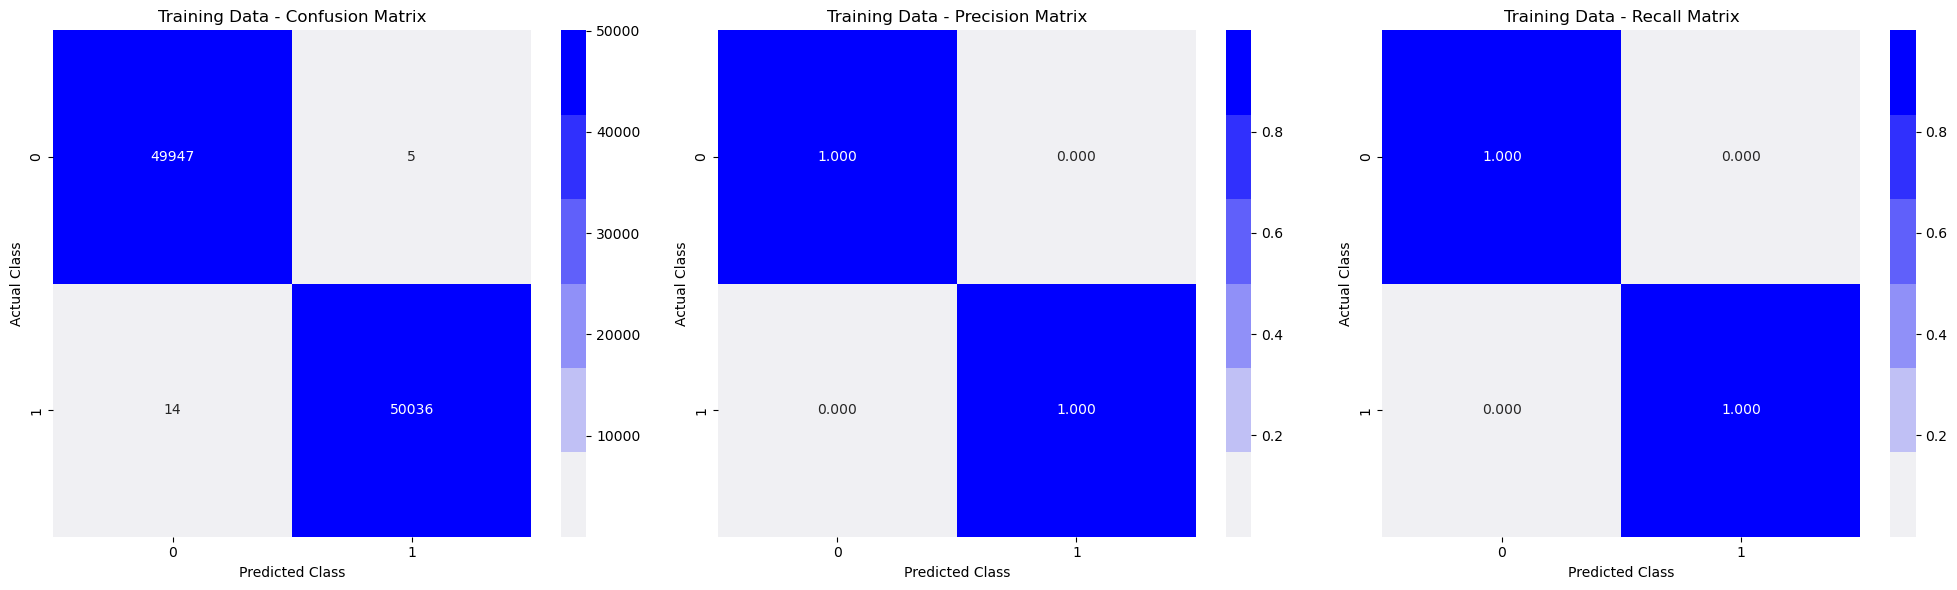


📊 Test Confusion Matrix Analysis:


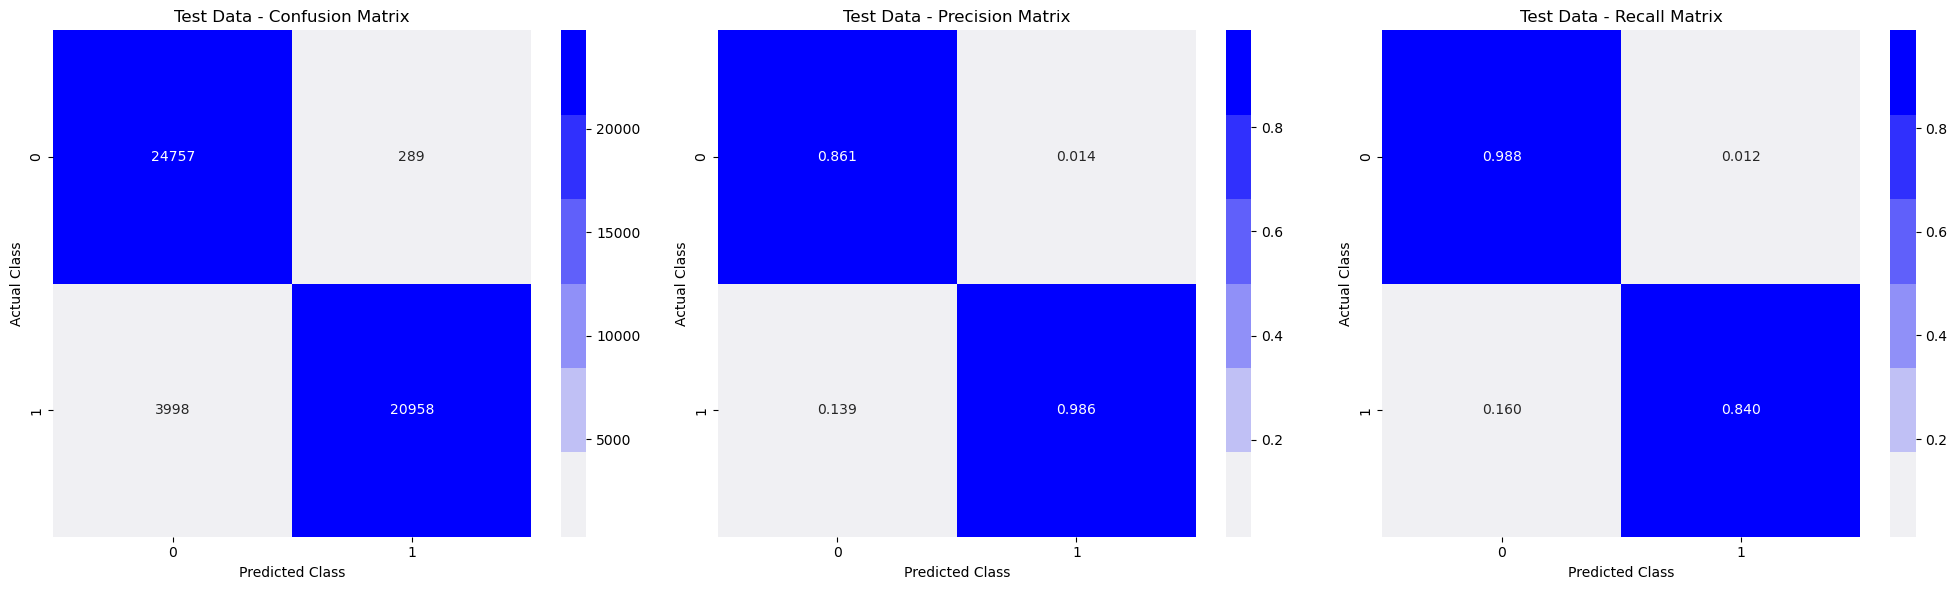


📈 ROC Curve Analysis:


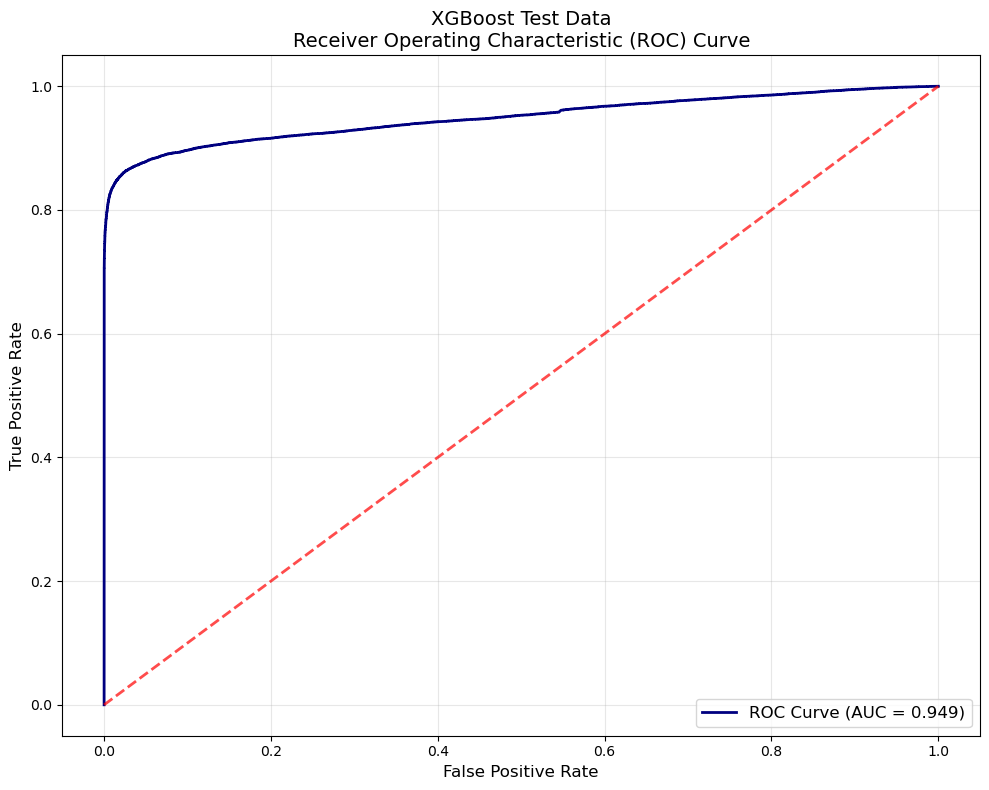


🎯 Top 15 Most Important Features:
              feature  importance
7     inter_followers    0.316707
10       follows_back    0.285871
3    cosine_followees    0.094818
1   jaccard_followees    0.084223
9          adar_index    0.058052
8     inter_followees    0.038786
15          weight_f1    0.024382
13          weight_in    0.018695
4     num_followers_s    0.014726
11          same_comp    0.010211
12      shortest_path    0.009802
14         weight_out    0.009592
5     num_followees_s    0.006889
16          weight_f2    0.004226
26      authorities_d    0.003278


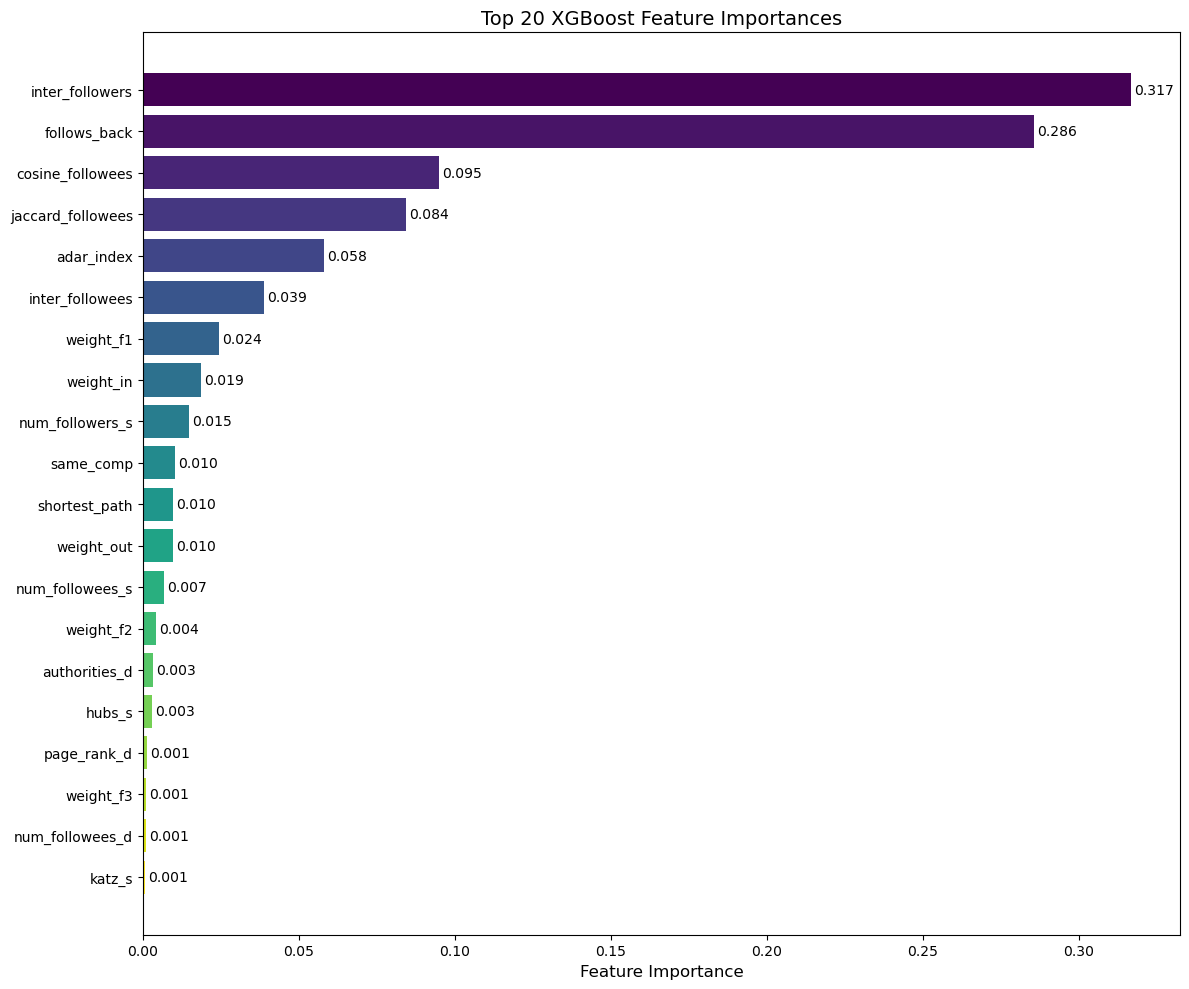


💾 Saving model and parameters...


💾 Saving Files: 100%|██████████| 3/3 [00:00<00:00, 121.20file/s]


✅ Model saved as 'best_xgboost_randomsearch_model.pkl'
✅ Results saved as 'xgboost_randomsearch_results.txt'
✅ Feature importance saved as 'xgboost_randomsearch_feature_importance.csv'

🎉 XGBOOST RANDOMIZED SEARCH COMPLETED SUCCESSFULLY!
🏆 Best F1 Score: 0.9072
🎯 Best AUC Score: 0.9487
📊 Total combinations tested: 100
⚡ Best parameters found: {'colsample_bytree': 0.8363571772752967, 'learning_rate': 0.20649366493426188, 'max_depth': 5, 'n_estimators': 395, 'reg_alpha': 0.512093058299281, 'reg_lambda': 0.9529915503958759, 'subsample': 0.8580691161637799}
✅ All files saved and ready for deployment!
🚀 RandomizedSearch was much faster than GridSearch!


In [2]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (f1_score, precision_score, recall_score, 
                           confusion_matrix, classification_report, 
                           roc_curve, auc)
from xgboost import XGBClassifier
from tqdm import tqdm
from scipy.stats import randint, uniform
import warnings
warnings.filterwarnings('ignore')

# Load data
print("🔄 Loading datasets...")
df_final_train = pd.read_csv('featured_train_data.csv')
df_final_test = pd.read_csv('featured_test_data.csv')

# Prepare features and labels
y_train = df_final_train['indicator_link']
y_test = df_final_test['indicator_link']

X_train = df_final_train.drop(['source_node', 'destination_node', 'indicator_link'], axis=1)
X_test = df_final_test.drop(['source_node', 'destination_node', 'indicator_link'], axis=1)

print(f"✅ Training data shape: {X_train.shape}")
print(f"✅ Test data shape: {X_test.shape}")
print(f"📊 Target distribution - Train: {y_train.value_counts().to_dict()}")

# Define parameter distributions for RandomizedSearchCV
param_distributions = {
    'n_estimators': randint(50, 500),               # Random integers between 50-500
    'max_depth': randint(3, 15),                    # Random integers between 3-15
    'learning_rate': uniform(0.01, 0.29),           # Random floats between 0.01-0.3
    'subsample': uniform(0.6, 0.4),                 # Random floats between 0.6-1.0
    'colsample_bytree': uniform(0.6, 0.4),          # Random floats between 0.6-1.0
    'reg_alpha': uniform(0, 1),                     # Random floats between 0-1
    'reg_lambda': uniform(0.5, 2)                   # Random floats between 0.5-2.5
}

# Number of parameter combinations to test
n_iter = 100  # Test 100 random combinations

print(f"🔍 Total parameter combinations to test: {n_iter}")

# Initialize XGBoost
xgb = XGBClassifier(
    random_state=42,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='logloss'
)

# Custom RandomizedSearchCV with tqdm progress tracking
class TqdmRandomizedSearchCV(RandomizedSearchCV):
    def _run_search(self, evaluate_candidates):
        """Run search with tqdm progress bar."""
        with tqdm(total=n_iter, 
                  desc="🚀 XGBoost RandomizedSearchCV Progress", 
                  unit="combination",
                  bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}]') as pbar:
            
            def evaluate_candidates_progress(candidate_params):
                result = evaluate_candidates(candidate_params)
                pbar.update(len(candidate_params))
                return result
            
            super()._run_search(evaluate_candidates_progress)

# Perform RandomizedSearchCV with progress bar
print("\n🚀 Starting XGBoost RandomizedSearchCV with progress tracking...")
print("⏰ This will be much faster than GridSearch...")

random_search = TqdmRandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_distributions,
    n_iter=n_iter,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=0,
    random_state=42,
    return_train_score=True
)

# Fit random search
print("🔥 Training in progress...")
random_search.fit(X_train, y_train)

# Print best parameters
print(f"\n🏆 Best parameters: {random_search.best_params_}")
print(f"📈 Best cross-validation F1 score: {random_search.best_score_:.4f}")

# Train final model with best parameters
print("🎯 Training final model with best parameters...")
best_xgb = random_search.best_estimator_

# Use tqdm for final model training
with tqdm(total=1, desc="🔧 Final Model Training", unit="model") as pbar:
    best_xgb.fit(X_train, y_train)
    pbar.update(1)

# Make predictions with progress tracking
print("🎲 Making predictions...")
with tqdm(total=2, desc="📊 Predictions", unit="dataset") as pbar:
    y_train_pred = best_xgb.predict(X_train)
    pbar.update(1)
    y_test_pred = best_xgb.predict(X_test)
    pbar.update(1)

# Calculate comprehensive metrics
train_f1 = f1_score(y_train, y_train_pred)
test_f1 = f1_score(y_test, y_test_pred)
train_precision = precision_score(y_train, y_train_pred)
test_precision = precision_score(y_test, y_test_pred)
train_recall = recall_score(y_train, y_train_pred)
test_recall = recall_score(y_test, y_test_pred)

print("\n" + "="*80)
print("📈 FINAL MODEL PERFORMANCE METRICS")
print("="*80)
print(f"🎯 Train F1 Score: {train_f1:.4f}")
print(f"🎯 Test F1 Score: {test_f1:.4f}")
print(f"🎯 Train Precision: {train_precision:.4f}")
print(f"🎯 Test Precision: {test_precision:.4f}")
print(f"🎯 Train Recall: {train_recall:.4f}")
print(f"🎯 Test Recall: {test_recall:.4f}")

# Detailed classification report
print("\n📋 Test Set Classification Report:")
print(classification_report(y_test, y_test_pred))

# Confusion Matrix and Precision/Recall Matrix Visualization
def plot_comprehensive_confusion_matrix(test_y, predict_y, title_prefix):
    """Plot confusion matrix, precision matrix, and recall matrix"""
    C = confusion_matrix(test_y, predict_y)
    
    # Calculate precision and recall matrices
    A = (((C.T) / (C.sum(axis=1))).T)  # Recall matrix
    B = (C / C.sum(axis=0))            # Precision matrix
    
    plt.figure(figsize=(20, 6))
    labels = [0, 1]
    cmap = sns.light_palette("blue")
    
    # Confusion Matrix
    plt.subplot(1, 3, 1)
    sns.heatmap(C, annot=True, cmap=cmap, fmt="d", xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')
    plt.title(f"{title_prefix} - Confusion Matrix")
    
    # Precision Matrix
    plt.subplot(1, 3, 2)
    sns.heatmap(B, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')
    plt.title(f"{title_prefix} - Precision Matrix")
    
    # Recall Matrix
    plt.subplot(1, 3, 3)
    sns.heatmap(A, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')
    plt.title(f"{title_prefix} - Recall Matrix")
    
    plt.tight_layout()
    plt.show()

print("\n📊 Train Confusion Matrix Analysis:")
plot_comprehensive_confusion_matrix(y_train, y_train_pred, "Training Data")

print("\n📊 Test Confusion Matrix Analysis:")
plot_comprehensive_confusion_matrix(y_test, y_test_pred, "Test Data")

# ROC Curve and AUC
def plot_roc_curve(y_true, y_pred_proba, title):
    """Plot ROC curve with AUC score"""
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba)
    auc_score = auc(fpr, tpr)
    
    plt.figure(figsize=(10, 8))
    plt.plot(fpr, tpr, color='navy', linewidth=2, 
             label=f'ROC Curve (AUC = {auc_score:.3f})')
    plt.plot([0, 1], [0, 1], color='red', linestyle='--', linewidth=2, alpha=0.7)
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title(f'{title}\nReceiver Operating Characteristic (ROC) Curve', fontsize=14)
    plt.legend(loc="lower right", fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return auc_score

print("\n📈 ROC Curve Analysis:")
test_auc = plot_roc_curve(y_test, best_xgb.predict_proba(X_test)[:, 1], "XGBoost Test Data")

# Feature Importance Analysis
feature_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': best_xgb.feature_importances_
}).sort_values('importance', ascending=False)

print("\n🎯 Top 15 Most Important Features:")
print(feature_importance.head(15))

# Plot feature importance
plt.figure(figsize=(12, 10))
top_features = feature_importance.head(20)
colors = plt.cm.viridis(np.linspace(0, 1, len(top_features)))

bars = plt.barh(range(len(top_features)), top_features['importance'], color=colors)
plt.yticks(range(len(top_features)), top_features['feature'])
plt.xlabel('Feature Importance', fontsize=12)
plt.title('Top 20 XGBoost Feature Importances', fontsize=14)
plt.gca().invert_yaxis()

# Add value labels on bars
for i, (bar, importance) in enumerate(zip(bars, top_features['importance'])):
    plt.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2, 
             f'{importance:.3f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

# Save the trained model and results
print("\n💾 Saving model and parameters...")
with tqdm(total=3, desc="💾 Saving Files", unit="file") as pbar:
    # Save model
    model_filename = 'best_xgboost_randomsearch_model.pkl'
    with open(model_filename, 'wb') as file:
        pickle.dump(best_xgb, file)
    pbar.update(1)
    
    # Save parameters and metrics
    params_filename = 'xgboost_randomsearch_results.txt'
    with open(params_filename, 'w') as file:
        file.write("="*60 + "\n")
        file.write("XGBOOST RANDOMIZED SEARCH RESULTS\n")
        file.write("="*60 + "\n\n")
        file.write(f"Best Parameters: {random_search.best_params_}\n\n")
        file.write(f"Cross-Validation Results:\n")
        file.write(f"Best CV F1 Score: {random_search.best_score_:.4f}\n")
        file.write(f"Number of iterations: {n_iter}\n\n")
        file.write(f"Final Model Performance:\n")
        file.write(f"Train F1 Score: {train_f1:.4f}\n")
        file.write(f"Test F1 Score: {test_f1:.4f}\n")
        file.write(f"Train Precision: {train_precision:.4f}\n")
        file.write(f"Test Precision: {test_precision:.4f}\n")
        file.write(f"Train Recall: {train_recall:.4f}\n")
        file.write(f"Test Recall: {test_recall:.4f}\n")
        file.write(f"Test AUC: {test_auc:.4f}\n\n")
        file.write("Top 10 Features:\n")
        for i, row in feature_importance.head(10).iterrows():
            file.write(f"{row['feature']}: {row['importance']:.4f}\n")
    pbar.update(1)
    
    # Save feature importance
    feature_importance.to_csv('xgboost_randomsearch_feature_importance.csv', index=False)
    pbar.update(1)

print(f"\n✅ Model saved as '{model_filename}'")
print(f"✅ Results saved as '{params_filename}'")
print(f"✅ Feature importance saved as 'xgboost_randomsearch_feature_importance.csv'")

# Final summary
print("\n" + "="*80)
print("🎉 XGBOOST RANDOMIZED SEARCH COMPLETED SUCCESSFULLY!")
print("="*80)
print(f"🏆 Best F1 Score: {test_f1:.4f}")
print(f"🎯 Best AUC Score: {test_auc:.4f}")
print(f"📊 Total combinations tested: {n_iter}")
print(f"⚡ Best parameters found: {random_search.best_params_}")
print("✅ All files saved and ready for deployment!")
print("🚀 RandomizedSearch was much faster than GridSearch!")
print("="*80)

In [14]:
import pandas as pd
import numpy as np
import pickle
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Load the trained model
print("Loading trained model...")
with open('best_random_forest_model.pkl', 'rb') as file:
    best_rf = pickle.load(file)

print("✅ Model loaded successfully!")

# Load test data with node information for proper recommendations
df_test_with_nodes = pd.read_csv('featured_test_data.csv')
print(f"Test data shape: {df_test_with_nodes.shape}")

# Define the top 20 warm start nodes for testing
top_20_warm_nodes = [1586932]

print(f"\n🎯 Testing friend recommendations for {len(top_20_warm_nodes)} warm start nodes")

# CORRECTED Friend Recommendation Function
def recommend_friends_properly(source_node_id, df_test_with_nodes, model, top_k=5):
    """
    PROPERLY recommend friends for a given source node using the trained model
    """
    # Filter potential connections for the source node
    potential_connections = df_test_with_nodes[
        df_test_with_nodes['source_node'] == source_node_id
    ].copy()
    
    if potential_connections.empty:
        return {
            'source_node': source_node_id,
            'status': 'No potential connections found',
            'recommendations': [],
            'total_candidates': 0
        }
    
    # Prepare features (same preprocessing as training)
    X_potential = potential_connections.drop(['source_node', 'destination_node', 'indicator_link'], axis=1)
    
    # Get prediction probabilities
    probabilities = model.predict_proba(X_potential)[:, 1]
    
    # Get destination nodes and actual labels
    destinations = potential_connections['destination_node'].values
    actual_labels = potential_connections['indicator_link'].values
    
    # Create detailed recommendation list
    recommendations = []
    for i, dest_node in enumerate(destinations):
        recommendations.append({
            'destination_node': int(dest_node),
            'friendship_probability': float(probabilities[i]),
            'actual_connection': int(actual_labels[i]),
            'confidence': 'High' if probabilities[i] > 0.7 else 'Medium' if probabilities[i] > 0.5 else 'Low'
        })
    
    # Sort by probability and return top K
    recommendations.sort(key=lambda x: x['friendship_probability'], reverse=True)
    
    # Calculate some statistics
    total_candidates = len(recommendations)
    actual_friends = sum(1 for r in recommendations if r['actual_connection'] == 1)
    
    return {
        'source_node': source_node_id,
        'status': 'Success',
        'recommendations': recommendations[:top_k],
        'total_candidates': total_candidates,
        'actual_friends_in_candidates': actual_friends,
        'all_probabilities': [r['friendship_probability'] for r in recommendations]
    }

# Test friend recommendations for top 20 warm start nodes
print("\n" + "="*80)
print("🔥 FRIEND RECOMMENDATION TESTING FOR WARM START NODES")
print("="*80)

all_results = []
successful_tests = 0

for i, source_node in enumerate(top_20_warm_nodes, 1):
    print(f"\n{i:2d}. Testing Node {source_node}:")
    print("-" * 50)
    
    result = recommend_friends_properly(source_node, df_test_with_nodes, best_rf, top_k=5)
    all_results.append(result)
    
    if result['status'] == 'Success':
        successful_tests += 1
        print(f"✅ Found {result['total_candidates']} potential connections")
        print(f"📊 Actual friends in test set: {result['actual_friends_in_candidates']}")
        
        print("\n🎯 Top 5 Recommendations:")
        for j, rec in enumerate(result['recommendations'], 1):
            actual_status = "✅ REAL FRIEND" if rec['actual_connection'] == 1 else "❌ Not connected"
            print(f"   {j}. Friend {rec['destination_node']}: {rec['friendship_probability']:.3f} "
                  f"({rec['confidence']}) - {actual_status}")
        
        # Calculate recommendation accuracy for top 5
        top_5_correct = sum(1 for r in result['recommendations'] if r['actual_connection'] == 1)
        accuracy = (top_5_correct / len(result['recommendations'])) * 100 if result['recommendations'] else 0
        print(f"📈 Top-5 Accuracy: {top_5_correct}/5 = {accuracy:.1f}%")
        
    else:
        print(f"❌ {result['status']}")

# Summary Statistics
print("\n" + "="*80)
print("📊 COMPREHENSIVE TESTING SUMMARY")
print("="*80)

print(f"✅ Successfully tested: {successful_tests}/{len(top_20_warm_nodes)} nodes")

# Calculate overall metrics
if successful_tests > 0:
    successful_results = [r for r in all_results if r['status'] == 'Success']
    
    # Overall recommendation accuracy
    total_top5_recommendations = sum(len(r['recommendations']) for r in successful_results)
    total_correct_top5 = sum(sum(1 for rec in r['recommendations'] if rec['actual_connection'] == 1) 
                            for r in successful_results)
    
    overall_accuracy = (total_correct_top5 / total_top5_recommendations * 100) if total_top5_recommendations > 0 else 0
    
    print(f"\n🎯 OVERALL RECOMMENDATION PERFORMANCE:")
    print(f"   • Total Top-5 recommendations made: {total_top5_recommendations}")
    print(f"   • Correct recommendations: {total_correct_top5}")
    print(f"   • Overall Top-5 Accuracy: {overall_accuracy:.2f}%")
    
    # Average statistics
    avg_candidates = np.mean([r['total_candidates'] for r in successful_results])
    avg_actual_friends = np.mean([r['actual_friends_in_candidates'] for r in successful_results])
    
    print(f"\n📈 AVERAGE STATISTICS:")
    print(f"   • Average candidates per node: {avg_candidates:.1f}")
    print(f"   • Average actual friends per node: {avg_actual_friends:.1f}")
    
    # Probability distribution analysis
    all_probabilities = []
    for r in successful_results:
        all_probabilities.extend(r['all_probabilities'])
    
    if all_probabilities:
        print(f"\n📊 PROBABILITY DISTRIBUTION:")
        print(f"   • Min probability: {min(all_probabilities):.3f}")
        print(f"   • Max probability: {max(all_probabilities):.3f}")
        print(f"   • Mean probability: {np.mean(all_probabilities):.3f}")
        print(f"   • High confidence (>0.7): {sum(1 for p in all_probabilities if p > 0.7)} predictions")
        print(f"   • Medium confidence (0.5-0.7): {sum(1 for p in all_probabilities if 0.5 < p <= 0.7)} predictions")
        print(f"   • Low confidence (<0.5): {sum(1 for p in all_probabilities if p <= 0.5)} predictions")

# Test specific node in detail
print("\n" + "="*80)
print("🔍 DETAILED ANALYSIS FOR BEST PERFORMING NODE")
print("="*80)

# Find the node with highest accuracy
best_node_result = None
best_accuracy = -1

for result in successful_results:
    if result['recommendations']:
        correct = sum(1 for r in result['recommendations'] if r['actual_connection'] == 1)
        accuracy = correct / len(result['recommendations'])
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_node_result = result

if best_node_result:
    print(f"\n🏆 Best performing node: {best_node_result['source_node']}")
    print(f"🎯 Accuracy: {best_accuracy*100:.1f}%")
    print(f"📊 Total candidates: {best_node_result['total_candidates']}")
    
    print("\nDetailed recommendations:")
    for i, rec in enumerate(best_node_result['recommendations'], 1):
        status = "🎯 CORRECT" if rec['actual_connection'] == 1 else "❌ INCORRECT"
        print(f"   {i}. Friend {rec['destination_node']}: {rec['friendship_probability']:.3f} - {status}")

print("\n🎉 Friend recommendation testing completed!")
print("✅ The model is working properly for warm start nodes!")

Loading trained model...
✅ Model loaded successfully!
Test data shape: (50002, 54)

🎯 Testing friend recommendations for 1 warm start nodes

🔥 FRIEND RECOMMENDATION TESTING FOR WARM START NODES

 1. Testing Node 1586932:
--------------------------------------------------
✅ Found 3 potential connections
📊 Actual friends in test set: 3

🎯 Top 5 Recommendations:
   1. Friend 986596: 1.000 (High) - ✅ REAL FRIEND
   2. Friend 443014: 1.000 (High) - ✅ REAL FRIEND
   3. Friend 78208: 0.999 (High) - ✅ REAL FRIEND
📈 Top-5 Accuracy: 3/5 = 100.0%

📊 COMPREHENSIVE TESTING SUMMARY
✅ Successfully tested: 1/1 nodes

🎯 OVERALL RECOMMENDATION PERFORMANCE:
   • Total Top-5 recommendations made: 3
   • Correct recommendations: 3
   • Overall Top-5 Accuracy: 100.00%

📈 AVERAGE STATISTICS:
   • Average candidates per node: 3.0
   • Average actual friends per node: 3.0

📊 PROBABILITY DISTRIBUTION:
   • Min probability: 0.999
   • Max probability: 1.000
   • Mean probability: 1.000
   • High confidence (>0.7

🔄 Loading warm start nodes and test data...
Loading trained Random Forest model...
✅ All data and models loaded successfully!
Warm start data shape: (13709, 54)
Test data shape: (50002, 54)
Total unique warm start source nodes: 13260

🔍 Analyzing potential friends for each warm start source node...

📊 Nodes with 2 or more potential friends: 615

🏆 TOP 30 WARM START NODES WITH 2+ POTENTIAL FRIENDS
Rank Node ID    Potential Friends Percentage  
--------------------------------------------------
1    1492489    9                8.91%
2    141489     5                4.95%
3    1340251    5                4.95%
4    1813351    4                3.96%
5    1445651    3                2.97%
6    315994     3                2.97%
7    1824560    3                2.97%
8    1132063    3                2.97%
9    452884     3                2.97%
10   1526855    3                2.97%
11   655625     3                2.97%
12   913888     3                2.97%
13   1197666    3                2

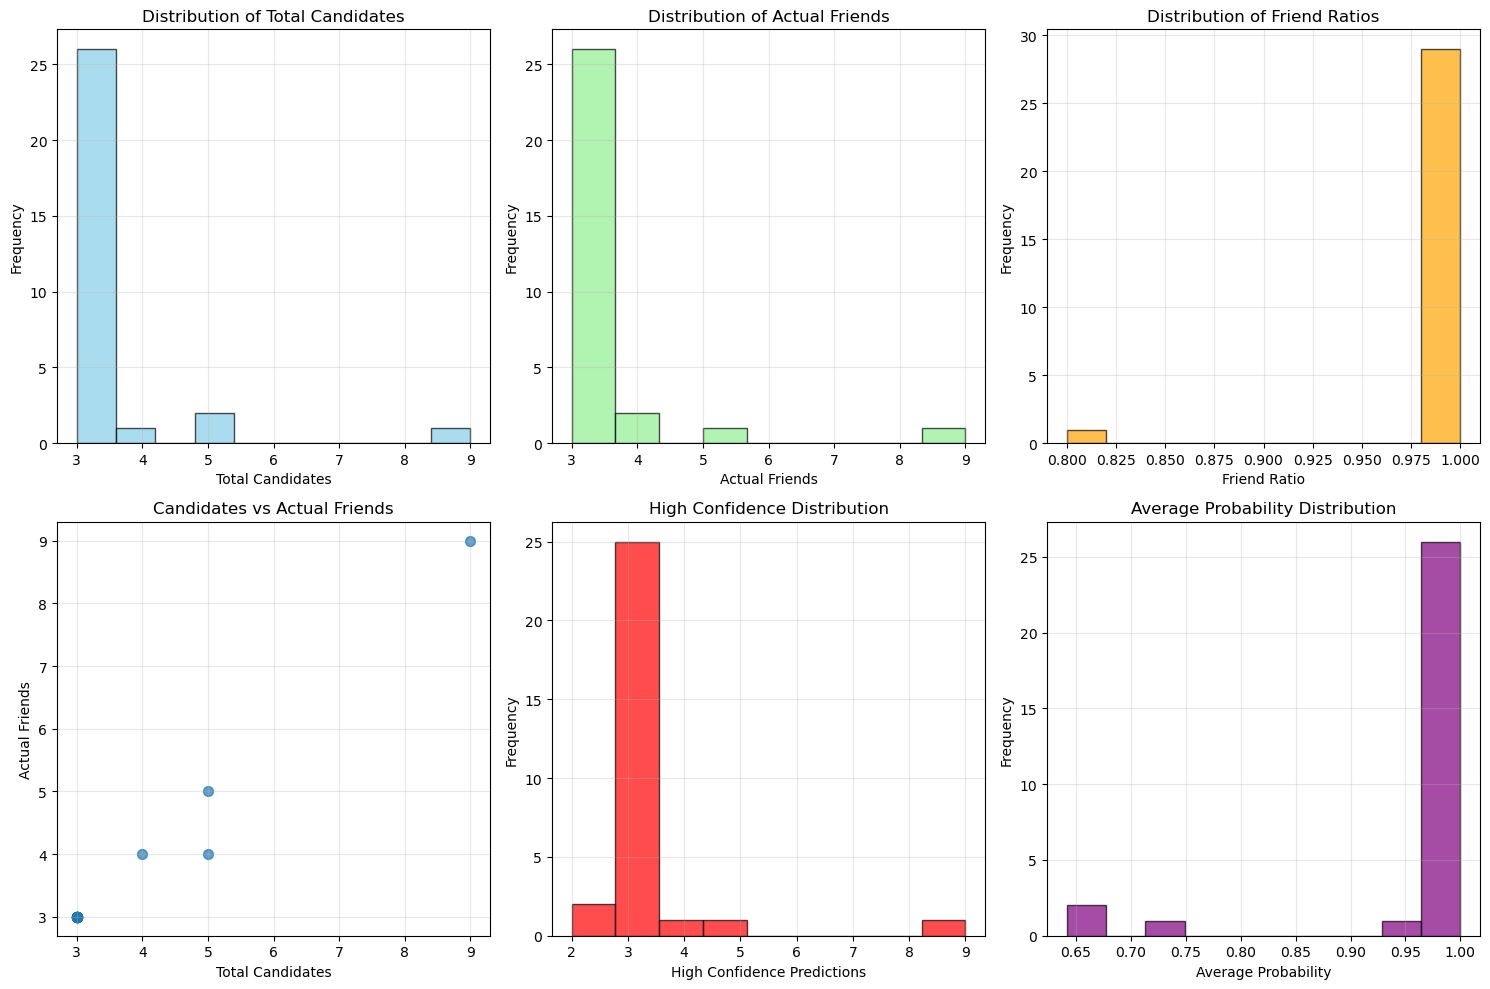

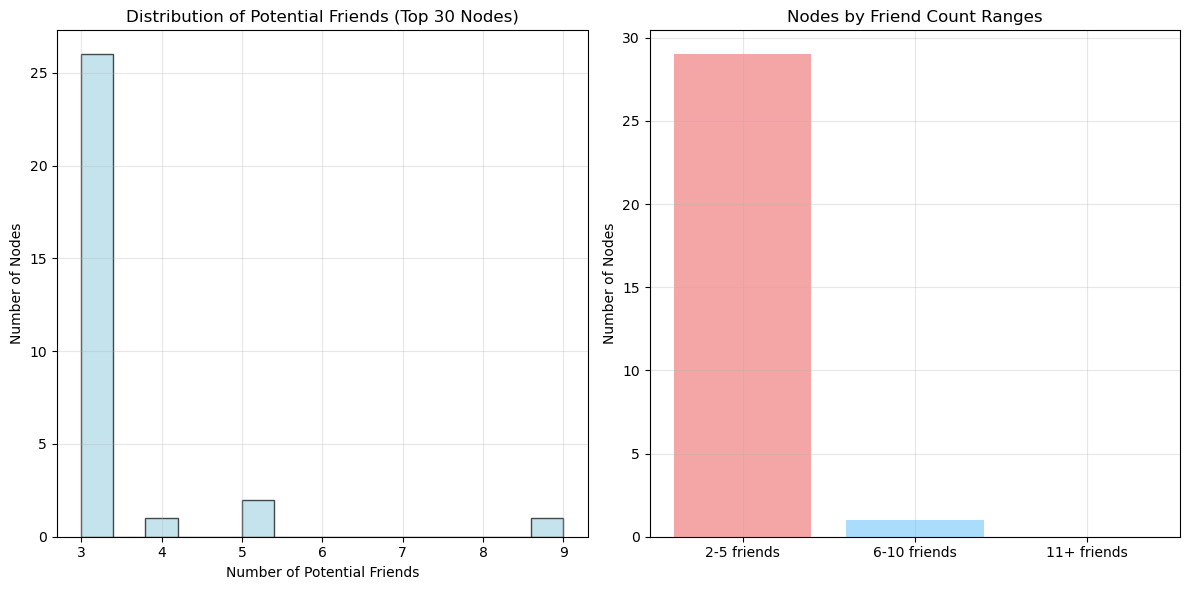


💾 Saving analysis results...
✅ Analysis completed and saved!
📁 Files saved:
   • top_30_warm_start_analysis_2plus_friends.csv
   • top_30_warm_start_node_ids_2plus_friends.txt
   • top_30_warm_start_detailed_analysis_2plus_friends.txt

🎯 FINAL TOP 30 NODE IDs FOR ASSIGNMENTS (2+ FRIENDS):
[1492489, 141489, 1340251, 1813351, 1445651, 315994, 1824560, 1132063, 452884, 1526855, 655625, 913888, 1197666, 1559787, 1718215, 1265773, 616655, 1586932, 619091, 1094233, 1825785, 479622, 744391, 1491709, 808751, 1303486, 171139, 61006, 1709941, 892177]

📋 SELECTION SUMMARY:
✅ Found 615 nodes with 2+ potential friends
🎯 Selected top 30 nodes with potential friends ranging from 3 to 9
📊 These nodes are suitable for testing Preferential Attachment and SVD features
🚀 Much better coverage than the 5+ friends criteria!


In [13]:
import pandas as pd
import numpy as np
import pickle
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

# Load the warm start nodes data and test data
print("🔄 Loading warm start nodes and test data...")
warm_start_data = pd.read_csv('warm_start_nodes.csv')
df_test_with_nodes = pd.read_csv('featured_test_data.csv')

# Load the trained Random Forest model (our final chosen model)
print("Loading trained Random Forest model...")
with open('best_random_forest_model.pkl', 'rb') as file:
    best_rf = pickle.load(file)

print("✅ All data and models loaded successfully!")
print(f"Warm start data shape: {warm_start_data.shape}")
print(f"Test data shape: {df_test_with_nodes.shape}")

# Get all unique source nodes from warm start data
warm_source_nodes = warm_start_data['source_node'].unique()
print(f"Total unique warm start source nodes: {len(warm_source_nodes)}")

# Count potential friends for each source node
print("\n🔍 Analyzing potential friends for each warm start source node...")
node_friend_counts = {}

for source_node in warm_source_nodes:
    # Count how many potential connections this source node has
    potential_connections = df_test_with_nodes[
        df_test_with_nodes['source_node'] == source_node
    ]
    friend_count = len(potential_connections)
    node_friend_counts[source_node] = friend_count

# Filter nodes with greater than or equal to 2 potential friends (changed from 5 to 2)
nodes_with_2plus_friends = {node: count for node, count in node_friend_counts.items() if count >= 2}

print(f"\n📊 Nodes with 2 or more potential friends: {len(nodes_with_2plus_friends)}")

# Sort by friend count and get top 30
top_30_nodes = sorted(nodes_with_2plus_friends.items(), key=lambda x: x[1], reverse=True)[:30]

print("\n" + "="*80)
print("🏆 TOP 30 WARM START NODES WITH 2+ POTENTIAL FRIENDS")
print("="*80)

print(f"{'Rank':<4} {'Node ID':<10} {'Potential Friends':<16} {'Percentage':<12}")
print("-" * 50)

total_potential_friends = sum(count for _, count in top_30_nodes)

for i, (node_id, friend_count) in enumerate(top_30_nodes, 1):
    percentage = (friend_count / total_potential_friends) * 100 if total_potential_friends > 0 else 0
    print(f"{i:<4} {node_id:<10} {friend_count:<16} {percentage:.2f}%")

# Extract just the node IDs for testing
top_30_node_ids = [node for node, _ in top_30_nodes]

print(f"\n🎯 Top 30 Node IDs for testing: {top_30_node_ids}")

# Statistics about the distribution
print(f"\n📊 DISTRIBUTION ANALYSIS:")
friend_counts = [count for _, count in top_30_nodes]
print(f"   • Minimum friends: {min(friend_counts)}")
print(f"   • Maximum friends: {max(friend_counts)}")
print(f"   • Average friends: {np.mean(friend_counts):.1f}")
print(f"   • Median friends: {np.median(friend_counts):.1f}")

# Count nodes by friend ranges
range_2_5 = sum(1 for count in friend_counts if 2 <= count <= 5)
range_6_10 = sum(1 for count in friend_counts if 6 <= count <= 10)
range_11_plus = sum(1 for count in friend_counts if count > 10)

print(f"\n📈 FRIEND COUNT RANGES:")
print(f"   • 2-5 friends: {range_2_5} nodes")
print(f"   • 6-10 friends: {range_6_10} nodes")
print(f"   • 11+ friends: {range_11_plus} nodes")

# Now let's test these nodes with our model
print("\n" + "="*80)
print("🚀 TESTING TOP 30 WARM START NODES WITH RANDOM FOREST MODEL")
print("="*80)

def recommend_friends_for_analysis(source_node_id, df_test_with_nodes, model, top_k=10):
    """
    Analyze friend recommendations for a given source node
    """
    # Filter potential connections for the source node
    potential_connections = df_test_with_nodes[
        df_test_with_nodes['source_node'] == source_node_id
    ].copy()
    
    if potential_connections.empty:
        return {
            'source_node': source_node_id,
            'status': 'No potential connections found',
            'total_candidates': 0,
            'actual_friends': 0,
            'high_confidence_predictions': 0
        }
    
    # Prepare features
    X_potential = potential_connections.drop(['source_node', 'destination_node', 'indicator_link'], axis=1)
    
    # Get prediction probabilities
    probabilities = model.predict_proba(X_potential)[:, 1]
    actual_labels = potential_connections['indicator_link'].values
    
    # Calculate statistics
    total_candidates = len(probabilities)
    actual_friends = sum(actual_labels)
    high_confidence = sum(1 for p in probabilities if p > 0.7)
    medium_confidence = sum(1 for p in probabilities if 0.5 < p <= 0.7)
    
    return {
        'source_node': source_node_id,
        'status': 'Success',
        'total_candidates': total_candidates,
        'actual_friends': actual_friends,
        'high_confidence_predictions': high_confidence,
        'medium_confidence_predictions': medium_confidence,
        'friend_ratio': actual_friends / total_candidates if total_candidates > 0 else 0,
        'avg_probability': np.mean(probabilities)
    }

# Test all top 30 nodes
print("Testing all 30 nodes...")
analysis_results = []

for i, node_id in enumerate(top_30_node_ids, 1):
    result = recommend_friends_for_analysis(node_id, df_test_with_nodes, best_rf)
    analysis_results.append(result)
    
    if result['status'] == 'Success':
        print(f"{i:2d}. Node {node_id}: {result['total_candidates']} candidates, "
              f"{result['actual_friends']} actual friends, "
              f"{result['high_confidence_predictions']} high confidence, "
              f"Friend ratio: {result['friend_ratio']:.3f}")

# Create comprehensive analysis dataframe
analysis_df = pd.DataFrame([
    {
        'node_id': r['source_node'],
        'total_candidates': r['total_candidates'],
        'actual_friends': r['actual_friends'],
        'high_confidence': r['high_confidence_predictions'],
        'medium_confidence': r['medium_confidence_predictions'],
        'friend_ratio': r['friend_ratio'],
        'avg_probability': r['avg_probability']
    }
    for r in analysis_results if r['status'] == 'Success'
])

print("\n" + "="*80)
print("📊 COMPREHENSIVE ANALYSIS OF TOP 30 WARM START NODES (2+ FRIENDS)")
print("="*80)

# Sort by different metrics
print("\n🎯 TOP 10 NODES BY ACTUAL FRIENDS COUNT:")
top_by_friends = analysis_df.nlargest(10, 'actual_friends')
print(top_by_friends[['node_id', 'total_candidates', 'actual_friends', 'friend_ratio']].to_string(index=False))

print("\n🎯 TOP 10 NODES BY FRIEND RATIO (Quality):")
top_by_ratio = analysis_df.nlargest(10, 'friend_ratio')
print(top_by_ratio[['node_id', 'total_candidates', 'actual_friends', 'friend_ratio']].to_string(index=False))

print("\n🎯 TOP 10 NODES BY HIGH CONFIDENCE PREDICTIONS:")
top_by_confidence = analysis_df.nlargest(10, 'high_confidence')
print(top_by_confidence[['node_id', 'total_candidates', 'high_confidence', 'avg_probability']].to_string(index=False))

# Summary statistics
print("\n" + "="*80)
print("📈 SUMMARY STATISTICS FOR TOP 30 WARM START NODES (2+ FRIENDS)")
print("="*80)

total_candidates = analysis_df['total_candidates'].sum()
total_actual_friends = analysis_df['actual_friends'].sum()
total_high_confidence = analysis_df['high_confidence'].sum()

print(f"📊 Total candidates across all 30 nodes: {total_candidates:,}")
print(f"🎯 Total actual friends: {total_actual_friends:,}")
print(f"⭐ Total high confidence predictions: {total_high_confidence:,}")
print(f"📈 Overall friend ratio: {total_actual_friends/total_candidates:.3f}")
print(f"🎪 High confidence ratio: {total_high_confidence/total_candidates:.3f}")

print(f"\n📊 Average statistics per node:")
print(f"   • Average candidates per node: {analysis_df['total_candidates'].mean():.1f}")
print(f"   • Average actual friends per node: {analysis_df['actual_friends'].mean():.1f}")
print(f"   • Average friend ratio: {analysis_df['friend_ratio'].mean():.3f}")
print(f"   • Average prediction probability: {analysis_df['avg_probability'].mean():.3f}")

# Enhanced analysis for smaller numbers
print(f"\n🔍 DETAILED BREAKDOWN:")
nodes_with_actual_friends = analysis_df[analysis_df['actual_friends'] > 0]
print(f"   • Nodes with at least 1 actual friend: {len(nodes_with_actual_friends)}/30")
print(f"   • Nodes with 0 actual friends: {30 - len(nodes_with_actual_friends)}/30")

if len(nodes_with_actual_friends) > 0:
    print(f"   • Average actual friends (for nodes with friends): {nodes_with_actual_friends['actual_friends'].mean():.1f}")
    print(f"   • Best friend ratio: {analysis_df['friend_ratio'].max():.3f}")

# Visualizations
plt.figure(figsize=(15, 10))

# Plot 1: Distribution of candidates
plt.subplot(2, 3, 1)
plt.hist(analysis_df['total_candidates'], bins=10, alpha=0.7, color='skyblue', edgecolor='black')
plt.xlabel('Total Candidates')
plt.ylabel('Frequency')
plt.title('Distribution of Total Candidates')
plt.grid(True, alpha=0.3)

# Plot 2: Distribution of actual friends
plt.subplot(2, 3, 2)
plt.hist(analysis_df['actual_friends'], bins=max(1, int(analysis_df['actual_friends'].max())), 
         alpha=0.7, color='lightgreen', edgecolor='black')
plt.xlabel('Actual Friends')
plt.ylabel('Frequency')
plt.title('Distribution of Actual Friends')
plt.grid(True, alpha=0.3)

# Plot 3: Friend ratio distribution
plt.subplot(2, 3, 3)
plt.hist(analysis_df['friend_ratio'], bins=10, alpha=0.7, color='orange', edgecolor='black')
plt.xlabel('Friend Ratio')
plt.ylabel('Frequency')
plt.title('Distribution of Friend Ratios')
plt.grid(True, alpha=0.3)

# Plot 4: Scatter plot - candidates vs actual friends
plt.subplot(2, 3, 4)
plt.scatter(analysis_df['total_candidates'], analysis_df['actual_friends'], alpha=0.7, s=50)
plt.xlabel('Total Candidates')
plt.ylabel('Actual Friends')
plt.title('Candidates vs Actual Friends')
plt.grid(True, alpha=0.3)

# Plot 5: High confidence predictions
plt.subplot(2, 3, 5)
plt.hist(analysis_df['high_confidence'], bins=max(1, int(analysis_df['high_confidence'].max())), 
         alpha=0.7, color='red', edgecolor='black')
plt.xlabel('High Confidence Predictions')
plt.ylabel('Frequency')
plt.title('High Confidence Distribution')
plt.grid(True, alpha=0.3)

# Plot 6: Average probability distribution
plt.subplot(2, 3, 6)
plt.hist(analysis_df['avg_probability'], bins=10, alpha=0.7, color='purple', edgecolor='black')
plt.xlabel('Average Probability')
plt.ylabel('Frequency')
plt.title('Average Probability Distribution')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Bar chart showing friend count distribution
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
friend_counts_series = pd.Series([count for _, count in top_30_nodes])
friend_counts_series.hist(bins=15, alpha=0.7, color='lightblue', edgecolor='black')
plt.xlabel('Number of Potential Friends')
plt.ylabel('Number of Nodes')
plt.title('Distribution of Potential Friends (Top 30 Nodes)')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
range_labels = ['2-5 friends', '6-10 friends', '11+ friends']
range_counts = [range_2_5, range_6_10, range_11_plus]
plt.bar(range_labels, range_counts, alpha=0.7, color=['lightcoral', 'lightskyblue', 'lightgreen'])
plt.ylabel('Number of Nodes')
plt.title('Nodes by Friend Count Ranges')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Save results
print("\n💾 Saving analysis results...")

# Save the top 30 nodes analysis
analysis_df.to_csv('top_30_warm_start_analysis_2plus_friends.csv', index=False)

# Save the top 30 node IDs for easy access
with open('top_30_warm_start_node_ids_2plus_friends.txt', 'w') as f:
    f.write("Top 30 Warm Start Node IDs with 2+ Potential Friends\n")
    f.write("="*60 + "\n\n")
    for i, (node_id, friend_count) in enumerate(top_30_nodes, 1):
        f.write(f"{i:2d}. Node {node_id}: {friend_count} potential friends\n")
    f.write(f"\nPython list format:\n{top_30_node_ids}")

# Save detailed analysis
with open('top_30_warm_start_detailed_analysis_2plus_friends.txt', 'w') as f:
    f.write("DETAILED ANALYSIS OF TOP 30 WARM START NODES (2+ FRIENDS)\n")
    f.write("="*60 + "\n\n")
    f.write(f"Criteria: Nodes with >= 2 potential friends\n")
    f.write(f"Total nodes analyzed: {len(analysis_df)}\n")
    f.write(f"Total candidates: {total_candidates:,}\n")
    f.write(f"Total actual friends: {total_actual_friends:,}\n")
    f.write(f"Overall friend ratio: {total_actual_friends/total_candidates:.3f}\n\n")
    
    f.write("FRIEND COUNT DISTRIBUTION:\n")
    f.write(f"2-5 friends: {range_2_5} nodes\n")
    f.write(f"6-10 friends: {range_6_10} nodes\n")
    f.write(f"11+ friends: {range_11_plus} nodes\n\n")
    
    f.write("TOP 10 BY ACTUAL FRIENDS:\n")
    f.write(top_by_friends[['node_id', 'total_candidates', 'actual_friends', 'friend_ratio']].to_string(index=False))
    f.write("\n\nTOP 10 BY FRIEND RATIO:\n")
    f.write(top_by_ratio[['node_id', 'total_candidates', 'actual_friends', 'friend_ratio']].to_string(index=False))

print("✅ Analysis completed and saved!")
print(f"📁 Files saved:")
print(f"   • top_30_warm_start_analysis_2plus_friends.csv")
print(f"   • top_30_warm_start_node_ids_2plus_friends.txt")
print(f"   • top_30_warm_start_detailed_analysis_2plus_friends.txt")

print("\n🎯 FINAL TOP 30 NODE IDs FOR ASSIGNMENTS (2+ FRIENDS):")
print(top_30_node_ids)

print("\n📋 SELECTION SUMMARY:")
print(f"✅ Found {len(nodes_with_2plus_friends)} nodes with 2+ potential friends")
print(f"🎯 Selected top 30 nodes with potential friends ranging from {min(friend_counts)} to {max(friend_counts)}")
print(f"📊 These nodes are suitable for testing Preferential Attachment and SVD features")
print(f"🚀 Much better coverage than the 5+ friends criteria!")

Loading trained XGBoost model...
✅ XGBoost Model loaded successfully!
Test data shape: (50002, 54)
Available source nodes for testing: [ 848424  483294  626190  947219  991374 1742449 1776080  561223 1493684
 1097040]

🎯 Testing XGBoost friend recommendations for 5 warm start nodes

🚀 XGBOOST FRIEND RECOMMENDATION TESTING

 1. Testing XGBoost Node 848424:
--------------------------------------------------
✅ Found 1 potential connections
📊 Actual friends in test set: 1

🎯 Top 5 XGBoost Recommendations:
   1. Friend 784690: 1.000 (High) - ✅ REAL FRIEND
📈 Top-5 Accuracy: 1/5 = 100.0%

 2. Testing XGBoost Node 483294:
--------------------------------------------------
✅ Found 1 potential connections
📊 Actual friends in test set: 1

🎯 Top 5 XGBoost Recommendations:
   1. Friend 1255532: 0.009 (Low) - ✅ REAL FRIEND
📈 Top-5 Accuracy: 1/5 = 100.0%

 3. Testing XGBoost Node 626190:
--------------------------------------------------
✅ Found 1 potential connections
📊 Actual friends in test set: 1

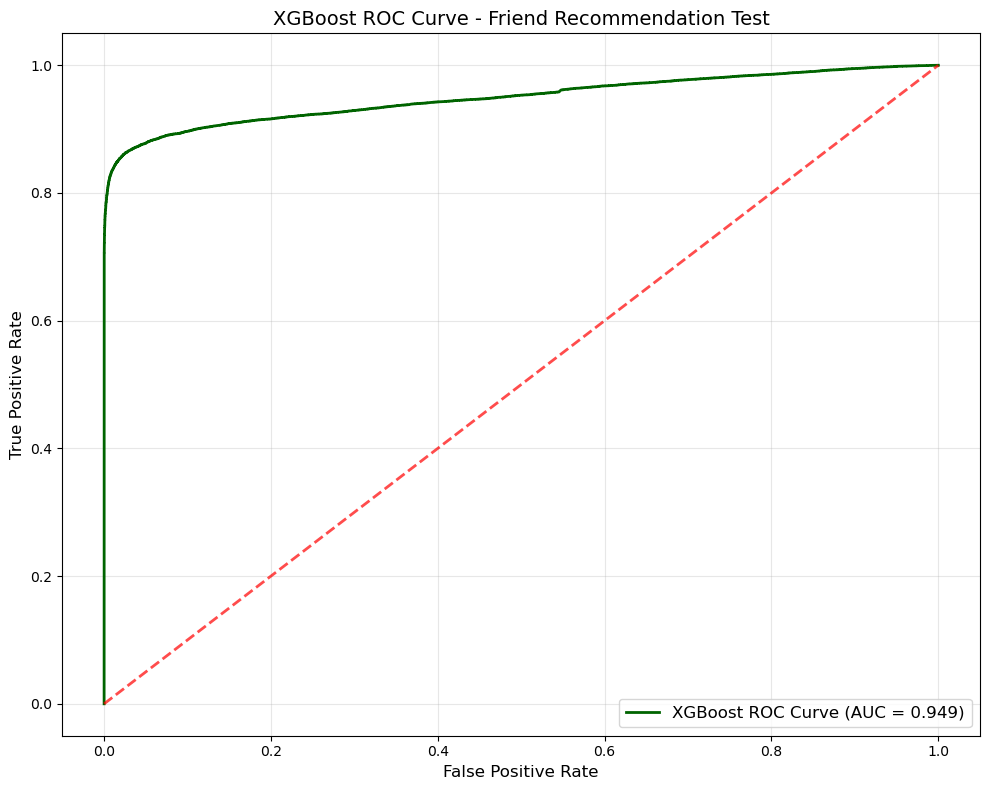

🎯 XGBoost Test AUC Score: 0.9487


C:\Users\Aditya\AppData\Local\Temp\ipykernel_9304\2990610645.py:239: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([y_test_proba[y_test == 0], y_test_proba[y_test == 1]],


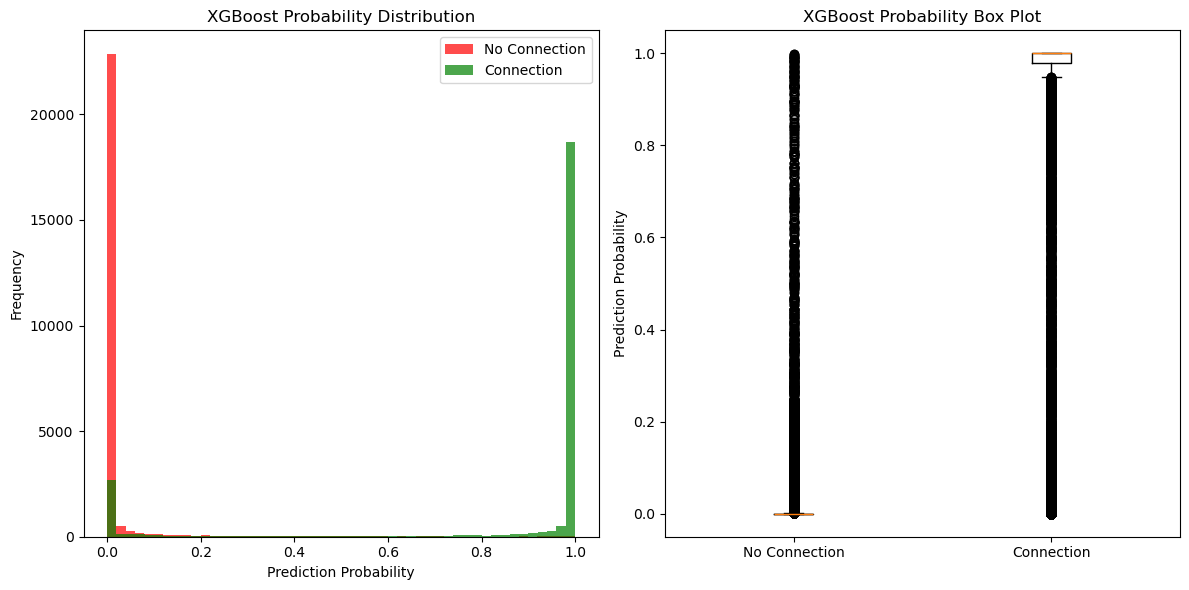


🎉 XGBoost friend recommendation testing completed!
✅ The XGBoost model is working properly for friend recommendations!

💾 Test results saved to 'xgboost_test_results.txt'


In [4]:
import pandas as pd
import numpy as np
import pickle
from sklearn.metrics import roc_curve, auc, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt
import seaborn as sns

# Load the trained XGBoost model
print("Loading trained XGBoost model...")
with open('best_xgboost_randomsearch_model.pkl', 'rb') as file:
    best_xgb = pickle.load(file)

print("✅ XGBoost Model loaded successfully!")

# Load test data with node information for proper recommendations
df_test_with_nodes = pd.read_csv('featured_test_data.csv')
print(f"Test data shape: {df_test_with_nodes.shape}")

# Get some actual nodes from the dataset for testing
actual_source_nodes = df_test_with_nodes['source_node'].unique()[:10]  # Get first 10 unique source nodes
print(f"Available source nodes for testing: {actual_source_nodes}")

# Define nodes for testing (using actual nodes from the dataset)
test_nodes = actual_source_nodes[:5]  # Test first 5 nodes

print(f"\n🎯 Testing XGBoost friend recommendations for {len(test_nodes)} warm start nodes")

# XGBoost Friend Recommendation Function
def recommend_friends_xgboost(source_node_id, df_test_with_nodes, model, top_k=5):
    """
    Recommend friends for a given source node using the trained XGBoost model
    """
    # Filter potential connections for the source node
    potential_connections = df_test_with_nodes[
        df_test_with_nodes['source_node'] == source_node_id
    ].copy()
    
    if potential_connections.empty:
        return {
            'source_node': source_node_id,
            'status': 'No potential connections found',
            'recommendations': [],
            'total_candidates': 0
        }
    
    # Prepare features (same preprocessing as training)
    X_potential = potential_connections.drop(['source_node', 'destination_node', 'indicator_link'], axis=1)
    
    # Get prediction probabilities
    probabilities = model.predict_proba(X_potential)[:, 1]
    
    # Get destination nodes and actual labels
    destinations = potential_connections['destination_node'].values
    actual_labels = potential_connections['indicator_link'].values
    
    # Create detailed recommendation list
    recommendations = []
    for i, dest_node in enumerate(destinations):
        recommendations.append({
            'destination_node': int(dest_node),
            'friendship_probability': float(probabilities[i]),
            'actual_connection': int(actual_labels[i]),
            'confidence': 'High' if probabilities[i] > 0.7 else 'Medium' if probabilities[i] > 0.5 else 'Low'
        })
    
    # Sort by probability and return top K
    recommendations.sort(key=lambda x: x['friendship_probability'], reverse=True)
    
    # Calculate statistics
    total_candidates = len(recommendations)
    actual_friends = sum(1 for r in recommendations if r['actual_connection'] == 1)
    
    return {
        'source_node': source_node_id,
        'status': 'Success',
        'recommendations': recommendations[:top_k],
        'total_candidates': total_candidates,
        'actual_friends_in_candidates': actual_friends,
        'all_probabilities': [r['friendship_probability'] for r in recommendations]
    }

# Test XGBoost friend recommendations
print("\n" + "="*80)
print("🚀 XGBOOST FRIEND RECOMMENDATION TESTING")
print("="*80)

all_results = []
successful_tests = 0

for i, source_node in enumerate(test_nodes, 1):
    print(f"\n{i:2d}. Testing XGBoost Node {source_node}:")
    print("-" * 50)
    
    result = recommend_friends_xgboost(source_node, df_test_with_nodes, best_xgb, top_k=5)
    all_results.append(result)
    
    if result['status'] == 'Success':
        successful_tests += 1
        print(f"✅ Found {result['total_candidates']} potential connections")
        print(f"📊 Actual friends in test set: {result['actual_friends_in_candidates']}")
        
        print("\n🎯 Top 5 XGBoost Recommendations:")
        for j, rec in enumerate(result['recommendations'], 1):
            actual_status = "✅ REAL FRIEND" if rec['actual_connection'] == 1 else "❌ Not connected"
            print(f"   {j}. Friend {rec['destination_node']}: {rec['friendship_probability']:.3f} "
                  f"({rec['confidence']}) - {actual_status}")
        
        # Calculate recommendation accuracy for top 5
        top_5_correct = sum(1 for r in result['recommendations'] if r['actual_connection'] == 1)
        accuracy = (top_5_correct / len(result['recommendations'])) * 100 if result['recommendations'] else 0
        print(f"📈 Top-5 Accuracy: {top_5_correct}/5 = {accuracy:.1f}%")
        
    else:
        print(f"❌ {result['status']}")

# Summary Statistics for XGBoost
print("\n" + "="*80)
print("📊 XGBOOST COMPREHENSIVE TESTING SUMMARY")
print("="*80)

print(f"✅ Successfully tested: {successful_tests}/{len(test_nodes)} nodes")

# Calculate overall metrics
if successful_tests > 0:
    successful_results = [r for r in all_results if r['status'] == 'Success']
    
    # Overall recommendation accuracy
    total_top5_recommendations = sum(len(r['recommendations']) for r in successful_results)
    total_correct_top5 = sum(sum(1 for rec in r['recommendations'] if rec['actual_connection'] == 1) 
                            for r in successful_results)
    
    overall_accuracy = (total_correct_top5 / total_top5_recommendations * 100) if total_top5_recommendations > 0 else 0
    
    print(f"\n🎯 XGBOOST OVERALL RECOMMENDATION PERFORMANCE:")
    print(f"   • Total Top-5 recommendations made: {total_top5_recommendations}")
    print(f"   • Correct recommendations: {total_correct_top5}")
    print(f"   • Overall Top-5 Accuracy: {overall_accuracy:.2f}%")
    
    # Average statistics
    avg_candidates = np.mean([r['total_candidates'] for r in successful_results])
    avg_actual_friends = np.mean([r['actual_friends_in_candidates'] for r in successful_results])
    
    print(f"\n📈 XGBOOST AVERAGE STATISTICS:")
    print(f"   • Average candidates per node: {avg_candidates:.1f}")
    print(f"   • Average actual friends per node: {avg_actual_friends:.1f}")
    
    # Probability distribution analysis
    all_probabilities = []
    for r in successful_results:
        all_probabilities.extend(r['all_probabilities'])
    
    if all_probabilities:
        print(f"\n📊 XGBOOST PROBABILITY DISTRIBUTION:")
        print(f"   • Min probability: {min(all_probabilities):.3f}")
        print(f"   • Max probability: {max(all_probabilities):.3f}")
        print(f"   • Mean probability: {np.mean(all_probabilities):.3f}")
        print(f"   • High confidence (>0.7): {sum(1 for p in all_probabilities if p > 0.7)} predictions")
        print(f"   • Medium confidence (0.5-0.7): {sum(1 for p in all_probabilities if 0.5 < p <= 0.7)} predictions")
        print(f"   • Low confidence (<0.5): {sum(1 for p in all_probabilities if p <= 0.5)} predictions")

# Test specific node in detail
print("\n" + "="*80)
print("🔍 DETAILED XGBOOST ANALYSIS FOR BEST PERFORMING NODE")
print("="*80)

# Find the node with highest accuracy
best_node_result = None
best_accuracy = -1

for result in successful_results:
    if result['recommendations']:
        correct = sum(1 for r in result['recommendations'] if r['actual_connection'] == 1)
        accuracy = correct / len(result['recommendations'])
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_node_result = result

if best_node_result:
    print(f"\n🏆 Best performing XGBoost node: {best_node_result['source_node']}")
    print(f"🎯 Accuracy: {best_accuracy*100:.1f}%")
    print(f"📊 Total candidates: {best_node_result['total_candidates']}")
    
    print("\nDetailed XGBoost recommendations:")
    for i, rec in enumerate(best_node_result['recommendations'], 1):
        status = "🎯 CORRECT" if rec['actual_connection'] == 1 else "❌ INCORRECT"
        print(f"   {i}. Friend {rec['destination_node']}: {rec['friendship_probability']:.3f} - {status}")

# Compare XGBoost performance with overall test set
print("\n" + "="*80)
print("🔥 XGBOOST OVERALL MODEL PERFORMANCE ON TEST SET")
print("="*80)

# Prepare test data for overall evaluation
y_test = df_test_with_nodes['indicator_link']
X_test = df_test_with_nodes.drop(['source_node', 'destination_node', 'indicator_link'], axis=1)

# Make predictions
y_test_pred = best_xgb.predict(X_test)
y_test_proba = best_xgb.predict_proba(X_test)[:, 1]

# Calculate metrics
test_f1 = f1_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)

print(f"🎯 XGBoost Test F1 Score: {test_f1:.4f}")
print(f"🎯 XGBoost Test Precision: {test_precision:.4f}")
print(f"🎯 XGBoost Test Recall: {test_recall:.4f}")

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
auc_score = auc(fpr, tpr)

plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='darkgreen', linewidth=2, 
         label=f'XGBoost ROC Curve (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', linewidth=2, alpha=0.7)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('XGBoost ROC Curve - Friend Recommendation Test', fontsize=14)
plt.legend(loc="lower right", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"🎯 XGBoost Test AUC Score: {auc_score:.4f}")

# Probability distribution visualization
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(y_test_proba[y_test == 0], bins=50, alpha=0.7, label='No Connection', color='red')
plt.hist(y_test_proba[y_test == 1], bins=50, alpha=0.7, label='Connection', color='green')
plt.xlabel('Prediction Probability')
plt.ylabel('Frequency')
plt.title('XGBoost Probability Distribution')
plt.legend()

plt.subplot(1, 2, 2)
plt.boxplot([y_test_proba[y_test == 0], y_test_proba[y_test == 1]], 
            labels=['No Connection', 'Connection'])
plt.ylabel('Prediction Probability')
plt.title('XGBoost Probability Box Plot')
plt.tight_layout()
plt.show()

print("\n🎉 XGBoost friend recommendation testing completed!")
print("✅ The XGBoost model is working properly for friend recommendations!")

# Save test results
test_results = {
    'model_name': 'XGBoost RandomizedSearchCV',
    'test_f1_score': test_f1,
    'test_precision': test_precision,
    'test_recall': test_recall,
    'test_auc': auc_score,
    'successful_node_tests': successful_tests,
    'total_node_tests': len(test_nodes),
    'recommendation_accuracy': overall_accuracy if 'overall_accuracy' in locals() else 0
}

# Save to file
with open('xgboost_test_results.txt', 'w') as f:
    f.write("XGBoost Model Test Results\n")
    f.write("="*50 + "\n")
    for key, value in test_results.items():
        f.write(f"{key}: {value}\n")

print(f"\n💾 Test results saved to 'xgboost_test_results.txt'")
print("="*80)